In [3]:

from google.colab import files

uploaded = files.upload()


Saving taxi_zone_lookup.csv to taxi_zone_lookup.csv
Saving yellow_tripdata_2025-03.parquet to yellow_tripdata_2025-03 (1).parquet
Saving yellow_tripdata_2025-02.parquet to yellow_tripdata_2025-02 (1).parquet
Saving yellow_tripdata_2025-01.parquet to yellow_tripdata_2025-01 (1).parquet


In [4]:

!pip install -q pyarrow

import pandas as pd
import numpy as np
import os

print("Libraries imported successfully!")


Libraries imported successfully!


In [5]:

parquet_files = [
    f for f in uploaded.keys()
    if f.lower().endswith(".parquet")
]

csv_files = [
    f for f in uploaded.keys()
    if f.lower().endswith(".csv")
]

print("Parquet files:", parquet_files)
print("CSV files:", csv_files)

# Load the zone lookup
zones = pd.read_csv(csv_files[0])

print("\nZone lookup shape:", zones.shape)
display(zones.head())


Parquet files: ['yellow_tripdata_2025-03 (1).parquet', 'yellow_tripdata_2025-02 (1).parquet', 'yellow_tripdata_2025-01 (1).parquet']
CSV files: ['taxi_zone_lookup.csv']

Zone lookup shape: (265, 4)


,LocationID,Borough,Zone,service_zone
0,1,EWR,Newark Airport,EWR
1,2,Queens,Jamaica Bay,Boro Zone
2,3,Bronx,Allerton/Pelham Gardens,Boro Zone
3,4,Manhattan,Alphabet City,Yellow Zone
4,5,Staten Island,Arden Heights,Boro Zone


In [6]:

trips = pd.concat(
    [pd.read_parquet(f) for f in parquet_files],
    ignore_index=True
)

print("Total records:", len(trips))
print("Total columns:", len(trips.columns))

display(trips.head())


Total records: 11198026
Total columns: 20


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
0,1,2025-03-01 00:17:16,2025-03-01 00:25:52,1.0,0.90,1.0,N,140,236,1,7.9,3.50,0.5,2.60,0.0,1.0,15.50,2.5,0.0,0.00
1,1,2025-03-01 00:37:38,2025-03-01 00:43:51,1.0,0.60,1.0,N,140,262,1,6.5,3.50,0.5,2.30,0.0,1.0,13.80,2.5,0.0,0.00
2,2,2025-03-01 00:24:35,2025-03-01 00:39:49,1.0,1.94,1.0,N,161,68,1,14.9,1.00,0.5,5.16,0.0,1.0,25.81,2.5,0.0,0.75
3,2,2025-03-01 00:56:16,2025-03-01 01:01:35,2.0,0.95,1.0,N,231,13,1,7.2,1.00,0.5,2.59,0.0,1.0,15.54,2.5,0.0,0.75
4,1,2025-03-01 00:01:44,2025-03-01 00:10:00,1.0,1.50,1.0,N,163,236,1,8.6,4.25,0.5,2.85,0.0,1.0,17.20,2.5,0.0,0.75


In [7]:

print("Dataset information:")
trips.info()

print("\nMissing values:")
display(trips.isnull().sum())

print("\nStatistical summary:")
display(trips.describe())


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11198026 entries, 0 to 11198025
Data columns (total 20 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   VendorID               int32         
 1   tpep_pickup_datetime   datetime64[us]
 2   tpep_dropoff_datetime  datetime64[us]
 3   passenger_count        float64       
 4   trip_distance          float64       
 5   RatecodeID             float64       
 6   store_and_fwd_flag     object        
 7   PULocationID           int32         
 8   DOLocationID           int32         
 9   payment_type           int64         
 10  fare_amount            float64       
 11  extra                  float64       
 12  mta_tax                float64       
 13  tip_amount             float64       
 14  tolls_amount           float64       
 15  improvement_surcharge  float64       
 16  total_amount           float64       
 17  congestion_surcharge   float64       
 18 

,0
VendorID,0
tpep_pickup_datetime,0
tpep_dropoff_datetime,0
passenger_count,2263749
trip_distance,0
RatecodeID,2263749
store_and_fwd_flag,2263749
PULocationID,0
DOLocationID,0
payment_type,0



Statistical summary:


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
count,1.119803e+07,11198026,11198026,8.934277e+06,1.119803e+07,8.934277e+06,1.119803e+07,1.119803e+07,1.119803e+07,1.119803e+07,1.119803e+07,1.119803e+07,1.119803e+07,1.119803e+07,1.119803e+07,1.119803e+07,8.934277e+06,8.934277e+06,1.119803e+07
mean,1.803277e+00,2025-02-17 03:02:19.286455,2025-02-17 03:17:49.412614,1.288654e+00,6.179361e+00,2.453865e+00,1.633140e+02,1.625278e+02,9.768549e-01,1.724147e+01,1.256459e+00,4.790461e-01,2.849041e+00,4.447485e-01,9.570464e-01,2.566808e+01,2.225126e+00,1.272556e-01,5.202578e-01
min,1.000000e+00,2007-12-05 18:45:00,2007-12-05 19:02:00,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,-1.807600e+03,-9.250000e+00,-5.000000e-01,-2.200000e+02,-1.421700e+02,-1.000000e+00,-1.832850e+03,-2.500000e+00,-1.750000e+00,-7.500000e-01
25%,2.000000e+00,2025-01-26 03:19:31,2025-01-26 03:31:36.250000,1.000000e+00,1.000000e+00,1.000000e+00,1.250000e+02,1.130000e+02,1.000000e+00,8.600000e+00,0.000000e+00,5.000000e-01,0.000000e+00,0.000000e+00,1.000000e+00,1.545000e+01,2.500000e+00,0.000000e+00,0.000000e+00
50%,2.000000e+00,2025-02-17 14:56:00,2025-02-17 15:11:05,1.000000e+00,1.720000e+00,1.000000e+00,1.610000e+02,1.620000e+02,1.000000e+00,1.280000e+01,0.000000e+00,5.000000e-01,2.250000e+00,0.000000e+00,1.000000e+00,2.025000e+01,2.500000e+00,0.000000e+00,7.500000e-01
75%,2.000000e+00,2025-03-11 08:14:55,2025-03-11 08:32:06.750000,1.000000e+00,3.240000e+00,1.000000e+00,2.330000e+02,2.340000e+02,1.000000e+00,2.050000e+01,2.500000e+00,5.000000e-01,3.900000e+00,0.000000e+00,1.000000e+00,2.842000e+01,2.500000e+00,0.000000e+00,7.500000e-01
max,7.000000e+00,2025-04-01 00:00:17,2025-04-03 14:07:50,9.000000e+00,3.201363e+05,9.900000e+01,2.650000e+02,2.650000e+02,5.000000e+00,8.633721e+05,2.255000e+01,1.050000e+01,4.400000e+02,9.168700e+02,1.000000e+00,8.633804e+05,2.500000e+00,6.750000e+00,1.500000e+00
std,4.823931e-01,NaN,NaN,7.352221e-01,5.818232e+02,1.151333e+01,6.541426e+01,6.983088e+01,7.230819e-01,2.619917e+02,1.851653e+00,1.347475e-01,3.765220e+00,2.005737e+00,2.716238e-01,2.623102e+02,9.054736e-01,4.815095e-01,3.587075e-01


In [8]:

# RIDESMART - DATA QUALITY INVESTIGATION

# 1. Check date range
print("DATE RANGE")
print("Earliest pickup:", trips["tpep_pickup_datetime"].min())
print("Latest pickup:", trips["tpep_pickup_datetime"].max())

# 2. Check records by month
print("\nRECORDS BY MONTH")

monthly_records = (
    trips.groupby(
        trips["tpep_pickup_datetime"].dt.to_period("M")
    )
    .size()
)

display(monthly_records)

# 3. Check invalid trip durations
duration = (
    trips["tpep_dropoff_datetime"] -
    trips["tpep_pickup_datetime"]
).dt.total_seconds() / 60

print("\nTRIP DURATION CHECK")
print("Zero or negative duration:", (duration <= 0).sum())
print("Duration above 24 hours:", (duration > 1440).sum())

# 4. Check invalid distances and fares
print("\nDISTANCE AND FARE CHECK")
print("Zero or negative distance:", (trips["trip_distance"] <= 0).sum())
print("Negative fares:", (trips["fare_amount"] < 0).sum())
print("Zero or negative total amount:", (trips["total_amount"] <= 0).sum())

# 5. Check location IDs
print("\nLOCATION CHECK")
print("Unique pickup locations:", trips["PULocationID"].nunique())
print("Unique dropoff locations:", trips["DOLocationID"].nunique())

# 6. Check duplicate records
print("\nDUPLICATE CHECK")
print("Duplicate rows:", trips.duplicated().sum())

# 7. Missing-value percentages
print("\nMISSING VALUE PERCENTAGES")
display(
    (trips.isnull().mean() * 100)
    .round(2)
    .sort_values(ascending=False)
)


DATE RANGE
Earliest pickup: 2007-12-05 18:45:00
Latest pickup: 2025-04-01 00:00:17

RECORDS BY MONTH


,0
tpep_pickup_datetime,
2007-12,1
2009-01,1
2024-12,21
2025-01,3475234
2025-02,3577542
2025-03,4145225
2025-04,2



TRIP DURATION CHECK
Zero or negative duration: 29495
Duration above 24 hours: 47

DISTANCE AND FARE CHECK
Zero or negative distance: 294386
Negative fares: 535497
Zero or negative total amount: 188504

LOCATION CHECK
Unique pickup locations: 261
Unique dropoff locations: 260

DUPLICATE CHECK
Duplicate rows: 0

MISSING VALUE PERCENTAGES


,0
passenger_count,20.22
congestion_surcharge,20.22
store_and_fwd_flag,20.22
RatecodeID,20.22
Airport_fee,20.22
tpep_dropoff_datetime,0.00
VendorID,0.00
tpep_pickup_datetime,0.00
DOLocationID,0.00
payment_type,0.00


In [9]:

# RIDESMART - DETAILED DATA QUALITY INSPECTION

# Create trip duration
trips["trip_duration_min"] = (
    trips["tpep_dropoff_datetime"] -
    trips["tpep_pickup_datetime"]
).dt.total_seconds() / 60

# A. Records outside our selected dates
outside = trips[
    (trips["tpep_pickup_datetime"] < "2025-01-01") |
    (trips["tpep_pickup_datetime"] >= "2025-04-01")
]

print("A. OUTSIDE DATE RANGE")
display(outside.head(10))

# B. Invalid trip durations
invalid_duration = trips[trips["trip_duration_min"] <= 0]

print("B. INVALID DURATIONS")
display(invalid_duration.head(10))

# C. Negative fares
negative_fares = trips[trips["fare_amount"] < 0]

print("C. NEGATIVE FARES")
display(negative_fares[
    ["fare_amount", "total_amount", "payment_type"]
].head(10))

# D. Zero distance trips
zero_distance = trips[trips["trip_distance"] <= 0]

print("D. ZERO/NEGATIVE DISTANCE")
display(zero_distance[
    ["trip_distance", "fare_amount", "total_amount"]
].head(10))

# E. Long duration trips
long_trips = trips[trips["trip_duration_min"] > 1440]

print("E. TRIPS ABOVE 24 HOURS")
display(long_trips[
    ["tpep_pickup_datetime",
     "tpep_dropoff_datetime",
     "trip_duration_min",
     "trip_distance"]
].head(10))


A. OUTSIDE DATE RANGE


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,...,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration_min
230843,2,2009-01-01 00:19:34,2009-01-01 01:10:21,6.0,10.77,1.0,N,138,239,2,...,5.0,0.5,0.00,6.94,1.0,70.39,2.5,1.75,0.00,50.783333
827675,2,2007-12-05 18:45:00,2007-12-05 19:02:00,1.0,3.00,1.0,N,142,234,2,...,1.0,0.5,0.00,0.00,1.0,22.75,2.5,0.00,0.75,17.000000
3226205,2,2025-04-01 00:00:07,2025-04-01 00:24:28,1.0,10.40,1.0,N,132,82,2,...,1.0,0.5,0.00,0.00,1.0,47.15,0.0,1.75,0.00,24.350000
3227804,2,2025-04-01 00:00:17,2025-04-01 00:18:42,5.0,3.68,1.0,N,43,166,2,...,1.0,0.5,0.00,0.00,1.0,26.25,2.5,0.00,0.75,18.416667
7723405,2,2024-12-31 23:30:03,2024-12-31 23:43:02,1.0,3.00,1.0,N,246,13,1,...,1.0,0.5,5.32,0.00,1.0,26.62,2.5,0.00,0.00,12.983333
7723487,2,2024-12-31 23:31:38,2024-12-31 23:41:48,1.0,1.03,1.0,N,43,140,2,...,1.0,0.5,0.00,0.00,1.0,15.70,2.5,0.00,0.00,10.166667
7723488,2,2024-12-31 23:46:38,2025-01-01 00:03:03,1.0,3.95,1.0,N,229,24,2,...,1.0,0.5,0.00,0.00,1.0,24.10,2.5,0.00,0.00,16.416667
7723661,2,2024-12-31 23:56:19,2025-01-01 00:11:19,6.0,2.28,1.0,N,68,107,1,...,1.0,0.5,3.98,0.00,1.0,23.88,2.5,0.00,0.00,15.000000
7723908,2,2024-12-31 23:55:37,2025-01-01 00:01:26,1.0,1.12,1.0,N,56,56,2,...,1.0,0.5,0.00,0.00,1.0,10.40,0.0,0.00,0.00,5.816667
7724112,2,2024-12-31 23:52:40,2025-01-01 00:23:03,1.0,6.72,1.0,N,114,151,1,...,1.0,0.5,7.90,0.00,1.0,47.40,2.5,0.00,0.00,30.383333


B. INVALID DURATIONS


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,...,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration_min
168,7,2025-03-01 00:30:08,2025-03-01 00:30:08,1.0,1.33,1.0,N,234,161,1,...,0.00,0.5,2.73,0.0,1.0,16.38,2.5,0.0,0.75,0.0
1030,7,2025-03-01 00:11:55,2025-03-01 00:11:55,1.0,1.54,1.0,N,163,238,1,...,0.00,0.5,3.15,0.0,1.0,18.90,2.5,0.0,0.75,0.0
1031,7,2025-03-01 00:51:49,2025-03-01 00:51:49,2.0,1.34,1.0,N,114,107,1,...,0.00,0.5,2.87,0.0,1.0,17.22,2.5,0.0,0.75,0.0
1032,7,2025-03-01 00:57:24,2025-03-01 00:57:24,1.0,0.95,1.0,N,107,170,1,...,0.00,0.5,2.59,0.0,1.0,15.54,2.5,0.0,0.75,0.0
1599,7,2025-03-01 00:55:49,2025-03-01 00:55:49,4.0,4.88,1.0,N,148,143,1,...,0.00,0.5,6.51,0.0,1.0,39.06,2.5,0.0,0.75,0.0
3860,1,2025-03-01 00:12:13,2025-03-01 00:12:13,2.0,0.00,1.0,N,87,264,2,...,4.25,0.5,0.00,0.0,1.0,16.45,2.5,0.0,0.75,0.0
3861,1,2025-03-01 00:21:44,2025-03-01 00:21:44,2.0,0.00,1.0,N,148,264,2,...,4.25,0.5,0.00,0.0,1.0,17.15,2.5,0.0,0.75,0.0
3862,1,2025-03-01 00:22:18,2025-03-01 00:22:18,2.0,0.00,1.0,N,148,264,2,...,4.25,0.5,0.00,0.0,1.0,17.15,2.5,0.0,0.75,0.0
3864,1,2025-03-01 00:24:06,2025-03-01 00:24:06,1.0,0.00,1.0,N,148,264,2,...,4.25,0.5,0.00,0.0,1.0,26.25,2.5,0.0,0.75,0.0
6084,7,2025-03-01 01:21:54,2025-03-01 01:21:54,2.0,2.87,1.0,N,107,43,1,...,0.00,0.5,6.04,0.0,1.0,30.19,2.5,0.0,0.75,0.0


C. NEGATIVE FARES


,fare_amount,total_amount,payment_type
112,-10.0,-15.75,4
157,-70.0,-74.75,2
362,-7.2,-12.95,4
423,-27.5,-33.25,4
503,-8.6,-14.35,4
516,-87.7,-93.45,2
639,-10.7,-16.45,4
665,-4.4,-9.40,4
804,-3.7,-8.70,4
853,-5.8,-11.55,2


D. ZERO/NEGATIVE DISTANCE


,trip_distance,fare_amount,total_amount
135,0.0,13.0,14.00
336,0.0,51.5,59.94
453,0.0,3.0,8.75
505,0.0,13.0,22.42
519,0.0,3.0,8.75
803,0.0,3.0,5.50
822,0.0,60.0,61.00
823,0.0,35.5,37.00
903,0.0,11.4,16.65
1366,0.0,3.0,8.75


E. TRIPS ABOVE 24 HOURS


,tpep_pickup_datetime,tpep_dropoff_datetime,trip_duration_min,trip_distance
8274,2025-03-01 01:20:23,2025-03-04 11:58:13,4957.833333,1.62
493086,2025-03-05 19:47:05,2025-03-07 13:41:26,2514.350000,3.92
549355,2025-03-06 12:46:13,2025-03-10 07:37:39,5451.433333,0.83
658681,2025-03-07 11:15:36,2025-03-09 05:10:12,2514.600000,1.08
2215450,2025-03-22 03:11:02,2025-03-26 11:46:52,6275.833333,14.55
2654017,2025-03-26 16:58:55,2025-03-28 06:02:19,2223.400000,9.39
3008802,2025-03-29 18:34:01,2025-03-31 10:40:01,2406.000000,18.58
3171235,2025-03-31 13:14:01,2025-04-01 19:38:36,1824.583333,0.66
3222411,2025-03-31 22:06:47,2025-04-03 14:07:50,3841.050000,0.92
3264908,2025-03-01 21:13:27,2025-03-03 16:00:34,2567.116667,5.80


In [10]:

# RIDESMART - FINAL QUALITY CHECK

# 1. Negative fare distribution by payment type
print("NEGATIVE FARES BY PAYMENT TYPE")

display(
    trips[trips["fare_amount"] < 0]
    ["payment_type"]
    .value_counts()
    .sort_index()
)

# 2. Zero distance by payment type
print("\nZERO DISTANCE BY PAYMENT TYPE")

display(
    trips[trips["trip_distance"] <= 0]
    ["payment_type"]
    .value_counts()
    .sort_index()
)

# 3. Pickup location validity
print("\nPICKUP LOCATION CHECK")

print("Missing pickup locations:",
      trips["PULocationID"].isna().sum())

print("Unique pickup zones:",
      trips["PULocationID"].nunique())

# 4. Check duration distribution
print("\nTRIP DURATION DISTRIBUTION")

display(
    trips["trip_duration_min"].describe(
        percentiles=[0.01, 0.05, 0.50, 0.95, 0.99]
    )
)

# 5. Check how many records have valid dates
valid_dates = trips[
    trips["tpep_pickup_datetime"].between(
        "2025-01-01",
        "2025-03-31 23:59:59"
    )
]

print("\nRecords within our project period:",
      len(valid_dates))


NEGATIVE FARES BY PAYMENT TYPE


,count
payment_type,
0,353160
1,47
2,43358
3,23791
4,115141



ZERO DISTANCE BY PAYMENT TYPE


,count
payment_type,
0,177032
1,60076
2,26346
3,14269
4,16662
5,1



PICKUP LOCATION CHECK
Missing pickup locations: 0
Unique pickup zones: 261

TRIP DURATION DISTRIBUTION


,trip_duration_min
count,1.119803e+07
mean,1.550210e+01
std,3.107532e+01
min,-5.147232e+04
1%,3.833333e-01
5%,3.416667e+00
50%,1.213333e+01
95%,3.718333e+01
99%,6.148333e+01
max,8.564667e+03



Records within our project period: 11198001


In [11]:
# RIDESMART - CREATE DEMAND DATASET

project_start = pd.Timestamp("2025-01-01")
project_end = pd.Timestamp("2025-04-01")  # exclusive

date_mask = (
    (trips["tpep_pickup_datetime"] >= project_start) &
    (trips["tpep_pickup_datetime"] < project_end)
)

trips_demand = trips.loc[
    date_mask,
    ["tpep_pickup_datetime", "PULocationID"]
].copy()

# Add time features for demand analysis
trips_demand["pickup_date"] = (
    trips_demand["tpep_pickup_datetime"].dt.date
)

trips_demand["pickup_hour"] = (
    trips_demand["tpep_pickup_datetime"].dt.hour
)

trips_demand["day_of_week"] = (
    trips_demand["tpep_pickup_datetime"].dt.dayofweek
)

print("Demand dataset shape:", trips_demand.shape)
print("Date range:")
print(trips_demand["tpep_pickup_datetime"].min())
print(trips_demand["tpep_pickup_datetime"].max())

display(trips_demand.head())

Demand dataset shape: (11198001, 5)
Date range:
2025-01-01 00:00:00
2025-03-31 23:59:59


,tpep_pickup_datetime,PULocationID,pickup_date,pickup_hour,day_of_week
0,2025-03-01 00:17:16,140,2025-03-01,0,5
1,2025-03-01 00:37:38,140,2025-03-01,0,5
2,2025-03-01 00:24:35,161,2025-03-01,0,5
3,2025-03-01 00:56:16,231,2025-03-01,0,5
4,2025-03-01 00:01:44,163,2025-03-01,0,5


In [12]:
print("Zone lookup columns:")
print(zones.columns.tolist())

display(zones.head())

print("Number of rows in zone lookup:", len(zones))
print("Unique LocationIDs:", zones["LocationID"].nunique())

Zone lookup columns:
['LocationID', 'Borough', 'Zone', 'service_zone']


,LocationID,Borough,Zone,service_zone
0,1,EWR,Newark Airport,EWR
1,2,Queens,Jamaica Bay,Boro Zone
2,3,Bronx,Allerton/Pelham Gardens,Boro Zone
3,4,Manhattan,Alphabet City,Yellow Zone
4,5,Staten Island,Arden Heights,Boro Zone


Number of rows in zone lookup: 265
Unique LocationIDs: 265


In [13]:
known_zones = set(zones["LocationID"])

unknown_zones = (
    set(trips_demand["PULocationID"].unique()) - known_zones
)

print("Pickup zones missing from lookup:", len(unknown_zones))
print("Unknown zone IDs:", sorted(unknown_zones))

Pickup zones missing from lookup: 0
Unknown zone IDs: []


join demand data with zone names

In [14]:
# RIDESMART - JOIN TAXI ZONE INFORMATION

trips_demand = trips_demand.merge(
    zones[["LocationID", "Borough", "Zone"]],
    left_on="PULocationID",
    right_on="LocationID",
    how="left",
    validate="many_to_one"
)

# Check the join
print("Demand dataset shape:", trips_demand.shape)
print("Missing boroughs:", trips_demand["Borough"].isna().sum())
print("Missing zone names:", trips_demand["Zone"].isna().sum())

display(trips_demand.head())

Demand dataset shape: (11198001, 8)
Missing boroughs: 4093
Missing zone names: 23298


,tpep_pickup_datetime,PULocationID,pickup_date,pickup_hour,day_of_week,LocationID,Borough,Zone
0,2025-03-01 00:17:16,140,2025-03-01,0,5,140,Manhattan,Lenox Hill East
1,2025-03-01 00:37:38,140,2025-03-01,0,5,140,Manhattan,Lenox Hill East
2,2025-03-01 00:24:35,161,2025-03-01,0,5,161,Manhattan,Midtown Center
3,2025-03-01 00:56:16,231,2025-03-01,0,5,231,Manhattan,TriBeCa/Civic Center
4,2025-03-01 00:01:44,163,2025-03-01,0,5,163,Manhattan,Midtown North


In [15]:
# RIDESMART - PICKUP DEMAND BY BOROUGH

borough_demand = (
    trips_demand
    .groupby("Borough")
    .size()
    .reset_index(name="total_pickups")
    .sort_values("total_pickups", ascending=False)
)

display(borough_demand)

,Borough,total_pickups
3,Manhattan,9827095
4,Queens,965052
1,Brooklyn,306011
0,Bronx,70406
6,Unknown,23298
2,EWR,1056
5,Staten Island,990


In [16]:
# RIDESMART - TOP 10 PICKUP ZONES

zone_demand = (
    trips_demand
    .groupby(["Borough", "Zone"])
    .size()
    .reset_index(name="total_pickups")
    .sort_values("total_pickups", ascending=False)
)

display(zone_demand.head(10))

,Borough,Zone,total_pickups
142,Manhattan,Midtown Center,513560
161,Manhattan,Upper East Side South,491957
160,Manhattan,Upper East Side North,456758
201,Queens,JFK Airport,433503
155,Manhattan,Times Sq/Theatre District,377216
148,Manhattan,Penn Station/Madison Sq West,365696
143,Manhattan,Midtown East,360560
134,Manhattan,Lincoln Square East,332385
159,Manhattan,Union Sq,312841
147,Manhattan,Murray Hill,303492


In [17]:
# RIDESMART - HOURLY PICKUP DEMAND

hourly_demand = (
    trips_demand
    .groupby("pickup_hour")
    .size()
    .reset_index(name="total_pickups")
)

hourly_demand["average_pickups"] = (
    hourly_demand["total_pickups"] / 90
)

display(hourly_demand)

,pickup_hour,total_pickups,average_pickups
0,0,336497,3738.855556
1,1,223669,2485.211111
2,2,144320,1603.555556
3,3,101258,1125.088889
4,4,76265,847.388889
5,5,80257,891.744444
6,6,161998,1799.977778
7,7,316816,3520.177778
8,8,439443,4882.700000
9,9,452425,5026.944444


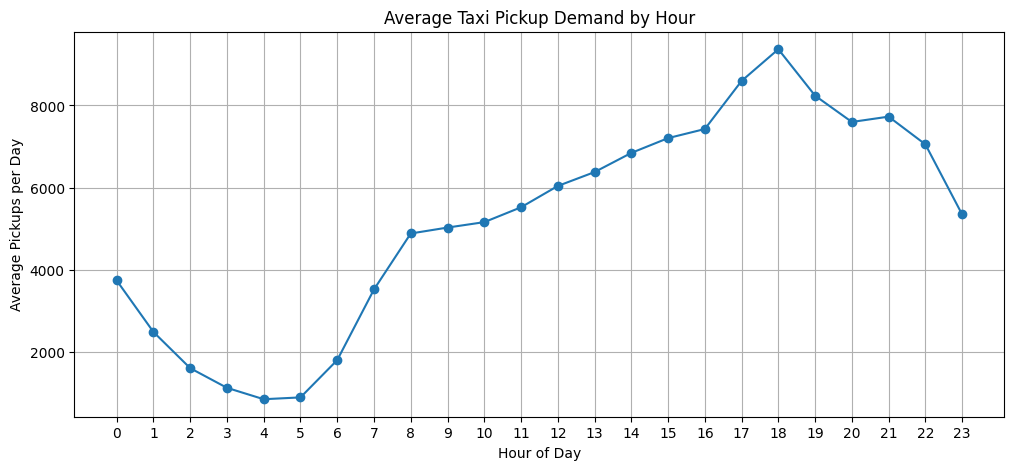

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    hourly_demand["pickup_hour"],
    hourly_demand["average_pickups"],
    marker="o"
)

plt.title("Average Taxi Pickup Demand by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Pickups per Day")
plt.xticks(range(24))
plt.grid(True)
plt.show()

compare weekdays and weekends

In [19]:
# RIDESMART - WEEKDAY VS WEEKEND DEMAND

# Monday = 0, Sunday = 6
trips_demand["day_type"] = trips_demand["day_of_week"].apply(
    lambda day: "Weekend" if day >= 5 else "Weekday"
)

# Count pickups for each hour and day type
day_hour_demand = (
    trips_demand
    .groupby(["day_type", "pickup_hour"])
    .size()
    .reset_index(name="total_pickups")
)

# Count the number of days in each category
days_count = (
    trips_demand[["pickup_date", "day_type"]]
    .drop_duplicates()
    .groupby("day_type")["pickup_date"]
    .nunique()
)

# Calculate average pickups per hour per day
day_hour_demand["average_pickups"] = day_hour_demand.apply(
    lambda row: row["total_pickups"] / days_count[row["day_type"]],
    axis=1
)

display(day_hour_demand.head(10))

,day_type,pickup_hour,total_pickups,average_pickups
0,Weekday,0,130138,2033.406250
1,Weekday,1,65337,1020.890625
2,Weekday,2,38101,595.328125
3,Weekday,3,26987,421.671875
4,Weekday,4,30970,483.906250
5,Weekday,5,57843,903.796875
6,Weekday,6,133765,2090.078125
7,Weekday,7,278291,4348.296875
8,Weekday,8,380529,5945.765625
9,Weekday,9,360835,5638.046875


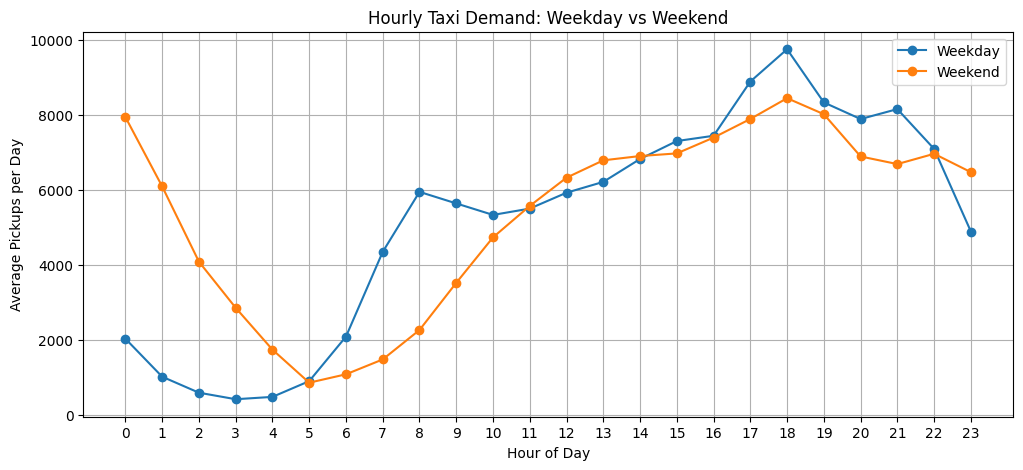

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

for day_type in ["Weekday", "Weekend"]:
    data = day_hour_demand[
        day_hour_demand["day_type"] == day_type
    ]

    plt.plot(
        data["pickup_hour"],
        data["average_pickups"],
        marker="o",
        label=day_type
    )

plt.title("Hourly Taxi Demand: Weekday vs Weekend")
plt.xlabel("Hour of Day")
plt.ylabel("Average Pickups per Day")
plt.xticks(range(24))
plt.legend()
plt.grid(True)
plt.show()

create a demand heatmap by borough and hour

In [21]:
# RIDESMART - BOROUGH VS HOURLY DEMAND

borough_hourly = (
    trips_demand
    .groupby(["Borough", "pickup_hour"])
    .size()
    .reset_index(name="total_pickups")
)

# Convert counts into average daily pickups
borough_days = (
    trips_demand[["pickup_date", "Borough"]]
    .drop_duplicates()
    .groupby("Borough")["pickup_date"]
    .nunique()
)

borough_hourly["average_pickups"] = borough_hourly.apply(
    lambda row: row["total_pickups"] / borough_days[row["Borough"]],
    axis=1
)

# Pivot data for heatmap
heatmap_data = borough_hourly.pivot(
    index="Borough",
    columns="pickup_hour",
    values="average_pickups"
)

display(heatmap_data)

pickup_hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
Borough,,,,,,,,,,,,,,,,,,,,,
Bronx,21.500000,12.800000,8.455556,9.400000,19.366667,28.033333,55.288889,70.466667,69.288889,46.588889,...,36.544444,34.166667,30.755556,32.888889,31.177778,29.177778,31.600000,25.488889,28.688889,31.388889
Brooklyn,143.200000,99.300000,77.933333,77.766667,80.577778,84.722222,124.166667,193.044444,225.411111,172.033333,...,134.455556,130.077778,125.911111,159.666667,199.077778,187.700000,158.355556,146.733333,193.211111,188.244444
EWR,0.022222,0.011111,0.033333,0.066667,0.188889,0.233333,0.422222,0.366667,0.200000,0.466667,...,1.444444,1.500000,1.344444,1.111111,0.777778,0.688889,0.388889,0.244444,0.033333,0.055556
Manhattan,3172.244444,2188.788889,1426.622222,958.866667,638.277778,615.233333,1355.755556,2888.366667,4231.344444,4436.011111,...,5984.944444,6315.944444,6523.877778,7720.333333,8481.855556,7324.788889,6727.888889,6874.355556,6185.211111,4501.411111
Queens,393.266667,178.211111,86.233333,75.744444,106.388889,160.577778,257.533333,355.277778,342.511111,358.222222,...,665.355556,702.866667,724.433333,662.844444,636.355556,678.455556,663.644444,664.633333,630.866667,613.211111
Staten Island,0.322222,0.166667,0.111111,0.122222,0.255556,0.588889,0.655556,1.477778,1.044444,0.322222,...,0.522222,0.555556,0.411111,0.211111,0.344444,0.277778,0.444444,0.400000,0.366667,0.622222
Unknown,5.966667,4.066667,2.577778,1.433333,1.077778,1.500000,5.188889,10.188889,11.933333,11.877778,...,18.233333,17.200000,16.288889,17.300000,17.455556,15.111111,13.500000,13.555556,11.777778,8.700000


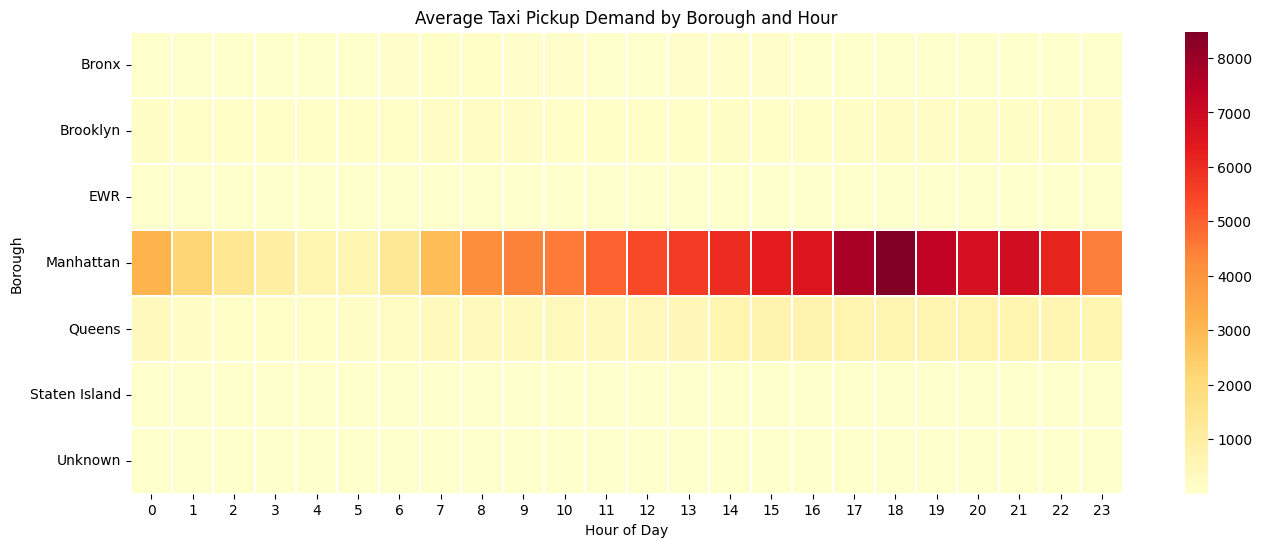

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(16, 6))

sns.heatmap(
    heatmap_data,
    cmap="YlOrRd",
    linewidths=0.3,
    fmt=".0f"
)

plt.title("Average Taxi Pickup Demand by Borough and Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Borough")

plt.show()

identify the top 5 demand zones in each borough

In [23]:
# RIDESMART - TOP 5 ZONES IN EACH BOROUGH

top_zones = (
    trips_demand
    .groupby(["Borough", "Zone"])
    .size()
    .reset_index(name="total_pickups")
    .sort_values(
        ["Borough", "total_pickups"],
        ascending=[True, False]
    )
)

top_5_per_borough = (
    top_zones
    .groupby("Borough")
    .head(5)
    .reset_index(drop=True)
)

display(top_5_per_borough)

,Borough,Zone,total_pickups
0,Bronx,Mott Haven/Port Morris,6925
1,Bronx,West Concourse,4113
2,Bronx,East Concourse/Concourse Village,3659
3,Bronx,Melrose South,3221
4,Bronx,Soundview/Castle Hill,2935
5,Brooklyn,Williamsburg (North Side),15223
6,Brooklyn,Crown Heights North,15119
7,Brooklyn,Williamsburg (South Side),12073
8,Brooklyn,East New York,11698
9,Brooklyn,Fort Greene,11560


analyse demand by zone and hour

In [24]:
# RIDESMART - HOURLY DEMAND FOR TOP 10 ZONES

top_10_zones = zone_demand.head(10)["Zone"].tolist()

top_zone_hourly = (
    trips_demand[
        trips_demand["Zone"].isin(top_10_zones)
    ]
    .groupby(["Zone", "pickup_hour"])
    .size()
    .reset_index(name="total_pickups")
)

display(top_zone_hourly.head(20))

,Zone,pickup_hour,total_pickups
0,JFK Airport,0,17002
1,JFK Airport,1,8176
2,JFK Airport,2,3108
3,JFK Airport,3,1943
4,JFK Airport,4,2237
5,JFK Airport,5,7354
6,JFK Airport,6,12659
7,JFK Airport,7,14137
8,JFK Airport,8,10624
9,JFK Airport,9,10487


actual zone-level heatmap

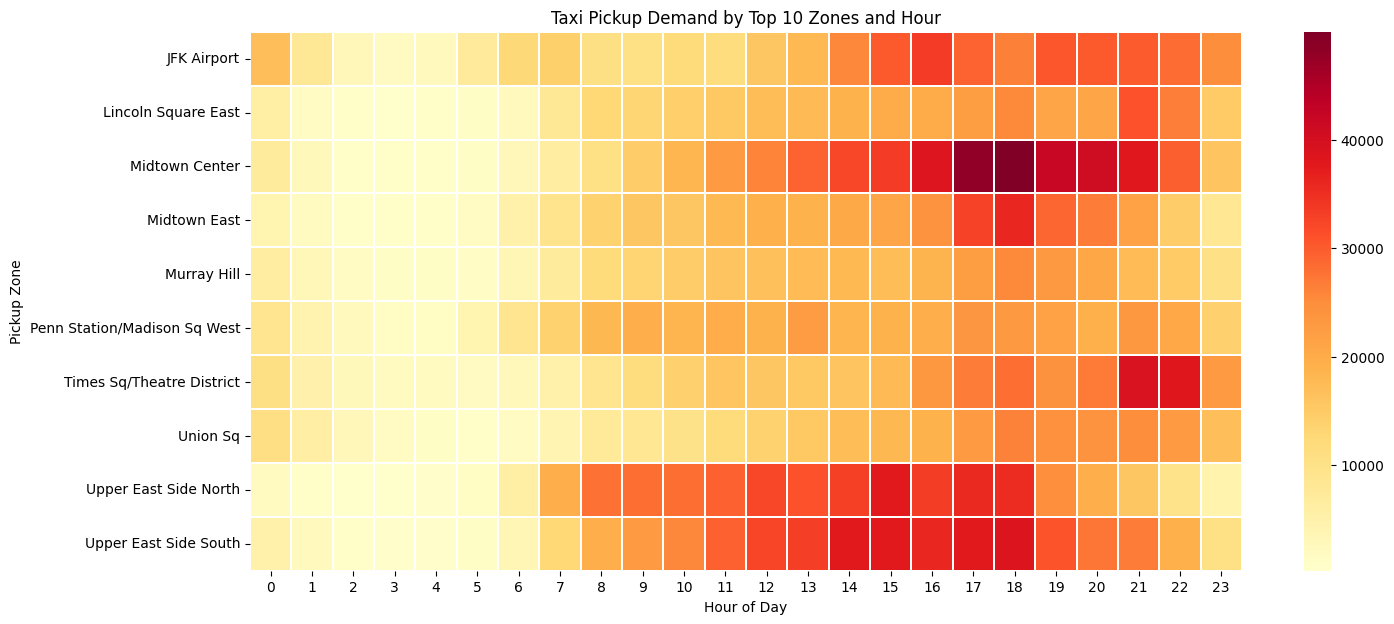

In [25]:
# RIDESMART - TOP 10 ZONES HOURLY HEATMAP

zone_heatmap = top_zone_hourly.pivot(
    index="Zone",
    columns="pickup_hour",
    values="total_pickups"
)

plt.figure(figsize=(16, 7))

sns.heatmap(
    zone_heatmap,
    cmap="YlOrRd",
    linewidths=0.3
)

plt.title("Taxi Pickup Demand by Top 10 Zones and Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Pickup Zone")
plt.show()

compare average daily demand

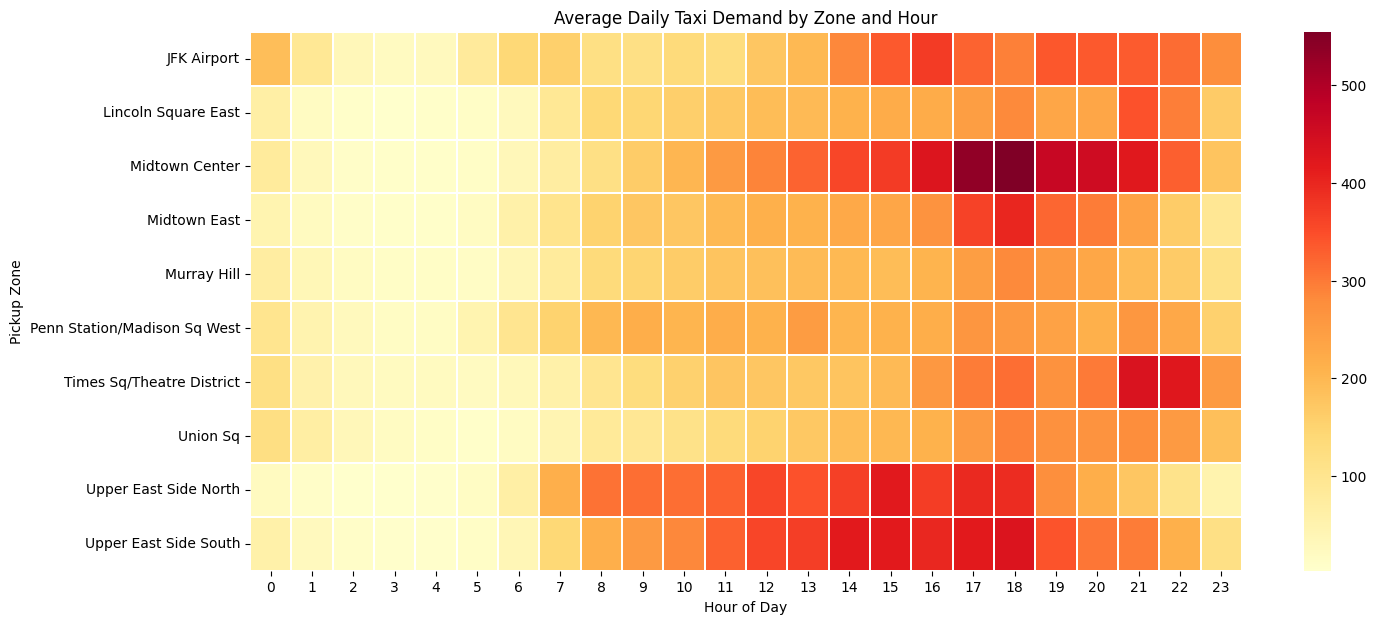

In [26]:
# RIDESMART - AVERAGE DAILY DEMAND BY ZONE AND HOUR

zone_days = (
    trips_demand[["Zone", "pickup_date"]]
    .drop_duplicates()
    .groupby("Zone")["pickup_date"]
    .nunique()
)

top_zone_hourly_avg = top_zone_hourly.copy()

top_zone_hourly_avg["average_daily_pickups"] = (
    top_zone_hourly_avg.apply(
        lambda row: row["total_pickups"] / zone_days[row["Zone"]],
        axis=1
    )
)

zone_avg_heatmap = top_zone_hourly_avg.pivot(
    index="Zone",
    columns="pickup_hour",
    values="average_daily_pickups"
)

plt.figure(figsize=(16, 7))

sns.heatmap(
    zone_avg_heatmap,
    cmap="YlOrRd",
    linewidths=0.3
)

plt.title("Average Daily Taxi Demand by Zone and Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Pickup Zone")
plt.show()

1. Key findings from the heatmap
Important project finding

 There is no single peak-demand hour that applies to every zone.
Zone	Demand pattern	Potential operational insigh
JFK Airport	Strong afternoon and evening demand	Increase availability during afternoon peaks
Midtown Center	Very high demand around 5–6 PM	Prioritise evening vehicle positioning
Midtown East	Strong evening peak	Prepare additional vehicles before evening
Upper East Side North	Strong morning-to-afternoon demand	Maintain availability earlier in the day
Upper East Side South	High demand across afternoon and evening	Maintain relatively consistent availability
Times Sq/Theatre District	Strong late-evening demand	Consider evening and night positioning
Lincoln Square East	Gradual increase through the day	Increase availability during afternoon
Penn Station/Madison Sq West	Stronger daytime and evening demand	Maintain coverage through busy periods
Murray Hill	Moderate daytime demand, rising in evening	Increase availability later in the day
Union Sq	Gradual daytime increase	Maintain coverage during afternoon and evening

Three interesting discoveries
1. JFK Airport behaves differently from Manhattan's city-centre zones.

JFK has a strong afternoon demand pattern, with activity remaining high into the evening.

2. Midtown Center has a particularly strong evening peak.

Its darkest cells appear around 5–6 PM, making it an important candidate for evening demand forecasting.

3. Upper East Side zones have substantial daytime demand.

Their demand builds earlier than some of the Midtown zones. This suggests that vehicle allocation should be time-dependent.



In [27]:
# RIDESMART - PEAK DEMAND HOUR BY ZONE

peak_zone_demand = (
    zone_avg_heatmap.idxmax(axis=1)
    .to_frame(name="peak_hour")
)

peak_zone_demand["peak_average_pickups"] = (
    zone_avg_heatmap.max(axis=1)
)

peak_zone_demand["lowest_hour"] = (
    zone_avg_heatmap.idxmin(axis=1)
)

peak_zone_demand["lowest_average_pickups"] = (
    zone_avg_heatmap.min(axis=1)
)

peak_zone_demand = peak_zone_demand.sort_values(
    "peak_average_pickups",
    ascending=False
)

display(peak_zone_demand)

,peak_hour,peak_average_pickups,lowest_hour,lowest_average_pickups
Zone,,,,
Midtown Center,18,554.944444,3,8.388889
Times Sq/Theatre District,21,435.800000,5,21.533333
Upper East Side South,18,430.800000,4,6.511111
Upper East Side North,15,421.022222,3,2.877778
Midtown East,18,401.511111,4,7.800000
JFK Airport,16,371.744444,3,21.588889
Lincoln Square East,21,344.911111,3,4.811111
Union Sq,18,290.344444,5,8.144444
Murray Hill,18,281.222222,3,11.866667


Peak-demand results
Zone	Peak hour	Average pickups at peak
Midtown Center	6 PM	554.9
Times Sq/Theatre District	9 PM	435.8
Upper East Side South	6 PM	430.8
Upper East Side North	3 PM	421.0
Midtown East	6 PM	401.5
JFK Airport	4 PM	371.7
Lincoln Square East	9 PM	344.9
Union Sq	6 PM	290.3
Murray Hill	6 PM	281.2
Penn Station/Madison Sq West	5 PM	263.7

These are average pickups per calendar day at the specified hour, based on the January–March data.

In [28]:
# RIDESMART - BUILD COMPLETE DAILY DEMAND DATA

import pandas as pd

# All 90 calendar days in the project period
all_dates = pd.date_range(
    start="2025-01-01",
    end="2025-03-31",
    freq="D"
).date

# Select the 10 busiest zones
top_10_zones = zone_demand.head(10)["Zone"].tolist()

# Count actual pickups by date, zone and hour
daily_counts = (
    trips_demand[
        trips_demand["Zone"].isin(top_10_zones)
    ]
    .groupby(["pickup_date", "Zone", "pickup_hour"])
    .size()
)

# Include combinations with zero pickups
full_index = pd.MultiIndex.from_product(
    [all_dates, top_10_zones, range(24)],
    names=["pickup_date", "Zone", "pickup_hour"]
)

daily_zone_demand = (
    daily_counts
    .reindex(full_index, fill_value=0)
    .reset_index(name="pickups")
)

print("Daily demand dataset:", daily_zone_demand.shape)
display(daily_zone_demand.head())

Daily demand dataset: (21600, 4)


,pickup_date,Zone,pickup_hour,pickups
0,2025-01-01,Midtown Center,0,274
1,2025-01-01,Midtown Center,1,248
2,2025-01-01,Midtown Center,2,150
3,2025-01-01,Midtown Center,3,67
4,2025-01-01,Midtown Center,4,33


In [29]:
# RIDESMART - CORRECTED AVERAGE DAILY DEMAND

zone_hour_average = (
    daily_zone_demand
    .groupby(["Zone", "pickup_hour"])["pickups"]
    .mean()
    .reset_index(name="average_daily_pickups")
)

corrected_heatmap = zone_hour_average.pivot(
    index="Zone",
    columns="pickup_hour",
    values="average_daily_pickups"
)

# Find peak hour for each zone
corrected_peak_table = (
    zone_hour_average
    .loc[
        zone_hour_average.groupby("Zone")[
            "average_daily_pickups"
        ].idxmax()
    ]
    .sort_values("average_daily_pickups", ascending=False)
)

display(corrected_peak_table)

,Zone,pickup_hour,average_daily_pickups
66,Midtown Center,18,554.944444
165,Times Sq/Theatre District,21,435.800000
234,Upper East Side South,18,430.800000
207,Upper East Side North,15,421.022222
90,Midtown East,18,401.511111
16,JFK Airport,16,371.744444
45,Lincoln Square East,21,344.911111
186,Union Sq,18,290.344444
114,Murray Hill,18,281.222222
137,Penn Station/Madison Sq West,17,263.700000


Verify the number of active days per zone

In [30]:
# RIDESMART - CHECK DAILY COVERAGE

coverage = (
    daily_zone_demand
    .groupby("Zone")
    .agg(
        active_days=("pickups", lambda x: (x.groupby(
            daily_zone_demand.loc[x.index, "pickup_date"]
        ).sum() > 0).sum())
    )
    .reset_index()
)

display(coverage)

,Zone,active_days
0,JFK Airport,90
1,Lincoln Square East,90
2,Midtown Center,90
3,Midtown East,90
4,Murray Hill,90
5,Penn Station/Madison Sq West,90
6,Times Sq/Theatre District,90
7,Union Sq,90
8,Upper East Side North,90
9,Upper East Side South,90


Prepare the forecasting dataset

In [31]:
# RIDESMART - FORECASTING DATASET

forecast_data = daily_zone_demand.copy()

# Convert date into datetime format
forecast_data["pickup_date"] = pd.to_datetime(
    forecast_data["pickup_date"]
)

# Create useful time features
forecast_data["day_of_week"] = (
    forecast_data["pickup_date"].dt.dayofweek
)

forecast_data["day_of_month"] = (
    forecast_data["pickup_date"].dt.day
)

forecast_data["month"] = (
    forecast_data["pickup_date"].dt.month
)

forecast_data["is_weekend"] = (
    forecast_data["day_of_week"] >= 5
).astype(int)

# Sort chronologically
forecast_data = forecast_data.sort_values(
    ["Zone", "pickup_date", "pickup_hour"]
).reset_index(drop=True)

print("Forecasting dataset shape:", forecast_data.shape)

display(forecast_data.head(10))

Forecasting dataset shape: (21600, 8)


,pickup_date,Zone,pickup_hour,pickups,day_of_week,day_of_month,month,is_weekend
0,2025-01-01,JFK Airport,0,233,2,1,1,0
1,2025-01-01,JFK Airport,1,74,2,1,1,0
2,2025-01-01,JFK Airport,2,72,2,1,1,0
3,2025-01-01,JFK Airport,3,20,2,1,1,0
4,2025-01-01,JFK Airport,4,23,2,1,1,0
5,2025-01-01,JFK Airport,5,87,2,1,1,0
6,2025-01-01,JFK Airport,6,168,2,1,1,0
7,2025-01-01,JFK Airport,7,126,2,1,1,0
8,2025-01-01,JFK Airport,8,110,2,1,1,0
9,2025-01-01,JFK Airport,9,105,2,1,1,0


Create historical demand features

In [32]:
# RIDESMART - HISTORICAL DEMAND FEATURES

forecast_data["lag_1"] = (
    forecast_data.groupby("Zone")["pickups"].shift(1)
)

forecast_data["lag_24"] = (
    forecast_data.groupby("Zone")["pickups"].shift(24)
)

forecast_data["lag_168"] = (
    forecast_data.groupby("Zone")["pickups"].shift(168)
)

display(forecast_data.head(30))

,pickup_date,Zone,pickup_hour,pickups,day_of_week,day_of_month,month,is_weekend,lag_1,lag_24,lag_168
0,2025-01-01,JFK Airport,0,233,2,1,1,0,NaN,NaN,NaN
1,2025-01-01,JFK Airport,1,74,2,1,1,0,233.0,NaN,NaN
2,2025-01-01,JFK Airport,2,72,2,1,1,0,74.0,NaN,NaN
3,2025-01-01,JFK Airport,3,20,2,1,1,0,72.0,NaN,NaN
4,2025-01-01,JFK Airport,4,23,2,1,1,0,20.0,NaN,NaN
5,2025-01-01,JFK Airport,5,87,2,1,1,0,23.0,NaN,NaN
6,2025-01-01,JFK Airport,6,168,2,1,1,0,87.0,NaN,NaN
7,2025-01-01,JFK Airport,7,126,2,1,1,0,168.0,NaN,NaN
8,2025-01-01,JFK Airport,8,110,2,1,1,0,126.0,NaN,NaN
9,2025-01-01,JFK Airport,9,105,2,1,1,0,110.0,NaN,NaN


In [33]:
# RIDESMART - CHECK MISSING LAG VALUES

print("Missing values in each column:")
display(forecast_data.isnull().sum())

print("\nTotal rows:", len(forecast_data))

print(
    "\nRows with all lag features available:",
    forecast_data.dropna(
        subset=["lag_1", "lag_24", "lag_168"]
    ).shape[0]
)

Missing values in each column:


,0
pickup_date,0
Zone,0
pickup_hour,0
pickups,0
day_of_week,0
day_of_month,0
month,0
is_weekend,0
lag_1,10
lag_24,240



Total rows: 21600

Rows with all lag features available: 19920


Prepare training and testing datasets

In [34]:
# RIDESMART - PREPARE MODEL DATA

model_data = forecast_data.dropna(
    subset=["lag_1", "lag_24", "lag_168"]
).copy()

# Training: January and February
train_data = model_data[
    model_data["pickup_date"] < "2025-03-01"
].copy()

# Testing: March
test_data = model_data[
    model_data["pickup_date"] >= "2025-03-01"
].copy()

print("Training rows:", len(train_data))
print("Testing rows:", len(test_data))

print("\nTraining date range:")
print(train_data["pickup_date"].min(), "to",
      train_data["pickup_date"].max())

print("\nTesting date range:")
print(test_data["pickup_date"].min(), "to",
      test_data["pickup_date"].max())

Training rows: 12480
Testing rows: 7440

Training date range:
2025-01-08 00:00:00 to 2025-02-28 00:00:00

Testing date range:
2025-03-01 00:00:00 to 2025-03-31 00:00:00


build our first forecasting model

In [35]:
# RIDESMART - MODEL PREPARATION

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

features = [
    "pickup_hour",
    "day_of_week",
    "day_of_month",
    "month",
    "is_weekend",
    "Zone",
    "lag_1",
    "lag_24",
    "lag_168"
]

target = "pickups"

# Convert zone names into numerical columns
X_train = pd.get_dummies(
    train_data[features],
    columns=["Zone"]
)

X_test = pd.get_dummies(
    test_data[features],
    columns=["Zone"]
)

# Ensure both datasets have identical feature columns
X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

y_train = train_data[target]
y_test = test_data[target]

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

Training feature shape: (12480, 18)
Testing feature shape: (7440, 18)


In [36]:
# RIDESMART - BASELINE MODEL

baseline_predictions = test_data["lag_168"]

baseline_mae = mean_absolute_error(
    y_test,
    baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)

baseline_r2 = r2_score(
    y_test,
    baseline_predictions
)

# RIDESMART - RANDOM FOREST MODEL

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

# Compare results
results = pd.DataFrame({
    "Model": ["Baseline", "Random Forest"],
    "MAE": [baseline_mae, rf_mae],
    "RMSE": [baseline_rmse, rf_rmse],
    "R2 Score": [baseline_r2, rf_r2]
})

display(results.round(3))

,Model,MAE,RMSE,R2 Score
0,Baseline,30.528,48.263,0.891
1,Random Forest,24.254,37.970,0.933


In [37]:
# RIDESMART - RANDOM FOREST FEATURE IMPORTANCE

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

display(feature_importance.head(15))

,Feature,Importance
7,lag_168,0.685352
5,lag_1,0.242179
6,lag_24,0.035735
0,pickup_hour,0.012056
1,day_of_week,0.008018
2,day_of_month,0.007231
3,month,0.001356
10,Zone_Midtown Center,0.001290
9,Zone_Lincoln Square East,0.001163
8,Zone_JFK Airport,0.001031


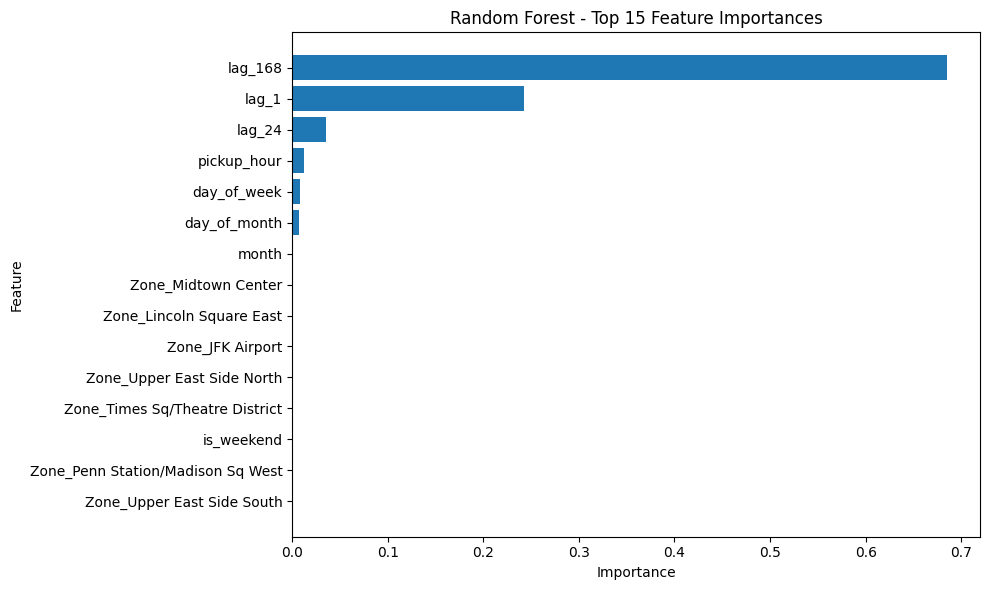

In [38]:
import matplotlib.pyplot as plt

top_features = feature_importance.head(15).sort_values(
    "Importance"
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Random Forest - Top 15 Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [39]:
# RIDESMART - ZONE LEVEL MODEL EVALUATION

evaluation = test_data[["Zone", "pickups"]].copy()

evaluation["actual"] = y_test.values
evaluation["predicted"] = rf_predictions

zone_performance = (
    evaluation.groupby("Zone")
    .apply(
        lambda group: pd.Series({
            "MAE": mean_absolute_error(
                group["actual"],
                group["predicted"]
            ),
            "RMSE": np.sqrt(
                mean_squared_error(
                    group["actual"],
                    group["predicted"]
                )
            )
        }),
        include_groups=False
    )
    .reset_index()
)

display(zone_performance.round(2))

,Zone,MAE,RMSE
0,JFK Airport,34.28,49.55
1,Lincoln Square East,23.89,42.39
2,Midtown Center,27.16,43.54
3,Midtown East,19.27,29.13
4,Murray Hill,17.36,24.40
5,Penn Station/Madison Sq West,29.81,44.50
6,Times Sq/Theatre District,24.93,37.30
7,Union Sq,19.13,29.18
8,Upper East Side North,23.29,36.23
9,Upper East Side South,23.40,35.91


visualise actual vs predicted demand

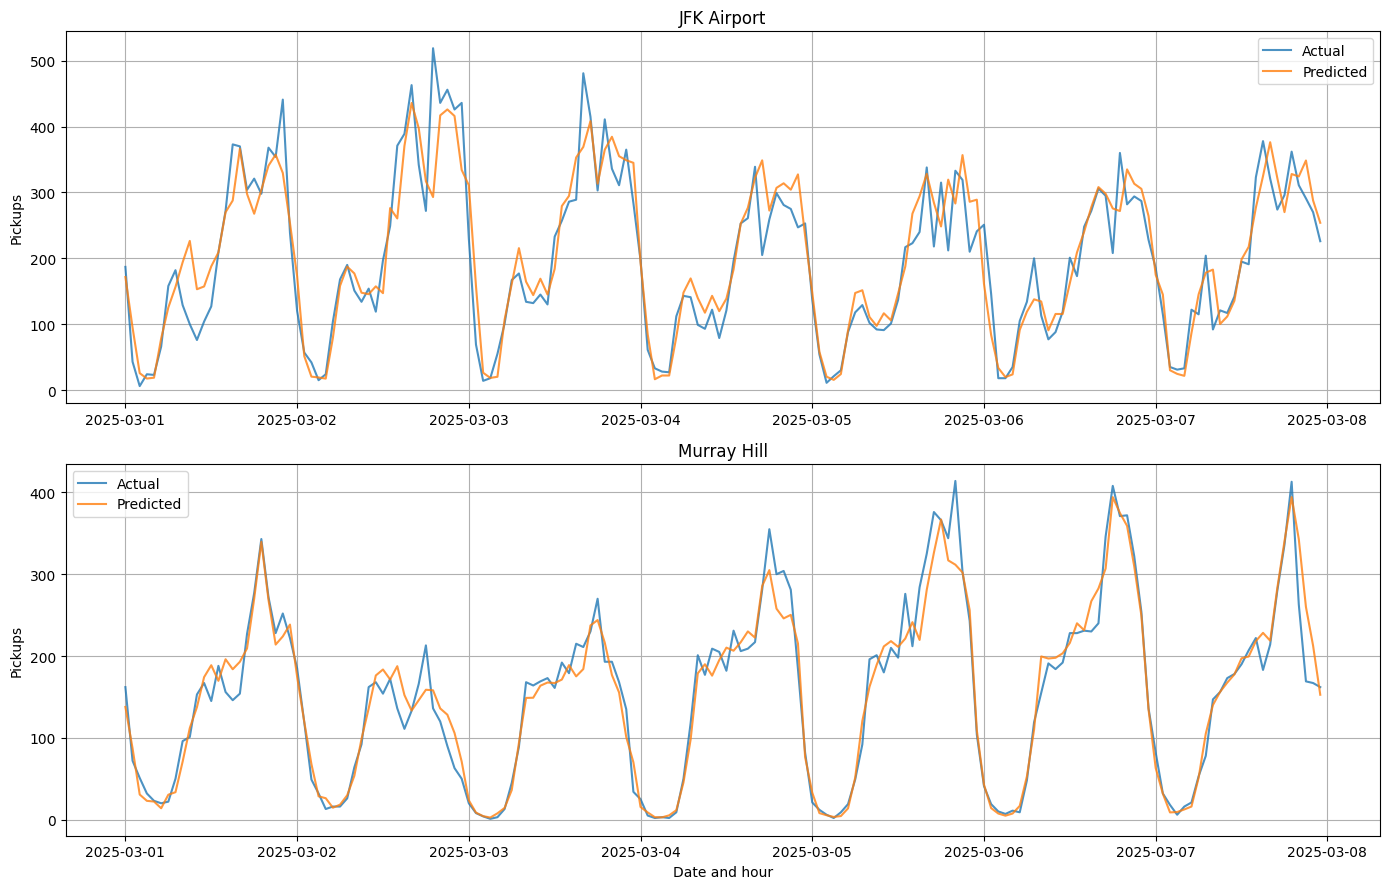

In [40]:
# RIDESMART - ACTUAL VS PREDICTED DEMAND

comparison = test_data[
    ["pickup_date", "Zone", "pickup_hour", "pickups"]
].copy()

comparison["predicted"] = rf_predictions

# Select two zones for comparison
selected_zones = [
    "JFK Airport",
    "Murray Hill"
]

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

for ax, zone in zip(axes, selected_zones):

    zone_data = comparison[
        comparison["Zone"] == zone
    ].copy()

    # Show one representative week in March
    zone_data = zone_data[
        zone_data["pickup_date"] < "2025-03-08"
    ]

    ax.plot(
        zone_data["pickup_date"] + pd.to_timedelta(
            zone_data["pickup_hour"], unit="h"
        ),
        zone_data["pickups"],
        label="Actual",
        alpha=0.8
    )

    ax.plot(
        zone_data["pickup_date"] + pd.to_timedelta(
            zone_data["pickup_hour"], unit="h"
        ),
        zone_data["predicted"],
        label="Predicted",
        alpha=0.8
    )

    ax.set_title(zone)
    ax.set_ylabel("Pickups")
    ax.legend()
    ax.grid(True)

plt.xlabel("Date and hour")
plt.tight_layout()
plt.show()

Select the top ten zones using training-period data

In [41]:
# RIDESMART - SELECT ZONES USING JANUARY AND FEBRUARY ONLY

train_period = trips_demand[
    trips_demand["pickup_date"] <
    pd.Timestamp("2025-03-01").date()
]

top_10_train_zones = (
    train_period.groupby("Zone")
    .size()
    .nlargest(10)
    .index.tolist()
)

print("Selected zones:")
print(top_10_train_zones)

Selected zones:
['Midtown Center', 'Upper East Side South', 'Upper East Side North', 'JFK Airport', 'Times Sq/Theatre District', 'Penn Station/Madison Sq West', 'Midtown East', 'Lincoln Square East', 'Union Sq', 'Murray Hill']


Rebuild the hourly demand dataset

In [42]:
# RIDESMART - REBUILD DEMAND DATASET

selected_data = trips_demand[
    trips_demand["Zone"].isin(top_10_train_zones)
].copy()

daily_counts = (
    selected_data
    .groupby(["pickup_date", "Zone", "pickup_hour"])
    .size()
)

full_index = pd.MultiIndex.from_product(
    [
        pd.date_range("2025-01-01", "2025-03-31").date,
        top_10_train_zones,
        range(24)
    ],
    names=["pickup_date", "Zone", "pickup_hour"]
)

daily_zone_demand = (
    daily_counts
    .reindex(full_index, fill_value=0)
    .reset_index(name="pickups")
)

forecast_data = daily_zone_demand.copy()

forecast_data["pickup_date"] = pd.to_datetime(
    forecast_data["pickup_date"]
)

forecast_data["day_of_week"] = (
    forecast_data["pickup_date"].dt.dayofweek
)

forecast_data["day_of_month"] = (
    forecast_data["pickup_date"].dt.day
)

forecast_data["month"] = (
    forecast_data["pickup_date"].dt.month
)

forecast_data["is_weekend"] = (
    forecast_data["day_of_week"] >= 5
).astype(int)

forecast_data = forecast_data.sort_values(
    ["Zone", "pickup_date", "pickup_hour"]
).reset_index(drop=True)

# Recreate historical features
for lag in [1, 24, 168]:
    forecast_data[f"lag_{lag}"] = (
        forecast_data.groupby("Zone")["pickups"].shift(lag)
    )

model_data = forecast_data.dropna(
    subset=["lag_1", "lag_24", "lag_168"]
).copy()

train_data = model_data[
    model_data["pickup_date"] < "2025-03-01"
].copy()

test_data = model_data[
    model_data["pickup_date"] >= "2025-03-01"
].copy()

print("Training rows:", len(train_data))
print("Testing rows:", len(test_data))

Training rows: 12480
Testing rows: 7440


Retrain and evaluate

In [43]:
# RIDESMART - FINAL FAIRER MODEL COMPARISON

features = [
    "pickup_hour",
    "day_of_week",
    "day_of_month",
    "month",
    "is_weekend",
    "Zone",
    "lag_1",
    "lag_24",
    "lag_168"
]

X_train = pd.get_dummies(
    train_data[features], columns=["Zone"]
)

X_test = pd.get_dummies(
    test_data[features], columns=["Zone"]
)

X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

y_train = train_data["pickups"]
y_test = test_data["pickups"]

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

baseline_predictions = test_data["lag_168"]

results = pd.DataFrame({
    "Model": ["Baseline", "Random Forest"],
    "MAE": [
        mean_absolute_error(y_test, baseline_predictions),
        mean_absolute_error(y_test, rf_predictions)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, baseline_predictions)),
        np.sqrt(mean_squared_error(y_test, rf_predictions))
    ],
    "R2": [
        r2_score(y_test, baseline_predictions),
        r2_score(y_test, rf_predictions)
    ]
})

display(results.round(3))

,Model,MAE,RMSE,R2
0,Baseline,30.528,48.263,0.891
1,Random Forest,24.254,37.970,0.933


In [44]:
print("Top 10 zones selected using Jan-Feb:")
print(top_10_train_zones)

print("\nTraining observations:", len(train_data))
print("Testing observations:", len(test_data))

print("\nTraining period:")
print(train_data["pickup_date"].min(),
      "to", train_data["pickup_date"].max())

print("\nTesting period:")
print(test_data["pickup_date"].min(),
      "to", test_data["pickup_date"].max())

Top 10 zones selected using Jan-Feb:
['Midtown Center', 'Upper East Side South', 'Upper East Side North', 'JFK Airport', 'Times Sq/Theatre District', 'Penn Station/Madison Sq West', 'Midtown East', 'Lincoln Square East', 'Union Sq', 'Murray Hill']

Training observations: 12480
Testing observations: 7440

Training period:
2025-01-08 00:00:00 to 2025-02-28 00:00:00

Testing period:
2025-03-01 00:00:00 to 2025-03-31 00:00:00


Generate the 24-hour forecasts

In [45]:
# RIDESMART - RECURSIVE 24-HOUR FORECASTING

from datetime import timedelta

# Actual historical pickup counts
actual_lookup = {
    (row.pickup_date, row.Zone, row.pickup_hour): row.pickups
    for row in daily_zone_demand.itertuples(index=False)
}

march_dates = pd.date_range(
    "2025-03-01",
    "2025-03-31",
    freq="D"
)

forecast_results = []

# Forecast one complete day at a time
for current_date in march_dates:

    forecast_day = current_date.date()

    for zone in top_10_train_zones:

        # Store this zone's predictions for the current day
        today_predictions = {}

        for hour in range(24):

            # Previous hour: use prediction within the day,
            # or actual previous-day demand at midnight.
            if hour == 0:
                lag_1 = actual_lookup[
                    (forecast_day - timedelta(days=1), zone, 23)
                ]
            else:
                lag_1 = today_predictions[hour - 1]

            # Previous day and previous week are historical actuals
            lag_24 = actual_lookup[
                (forecast_day - timedelta(days=1), zone, hour)
            ]

            lag_168 = actual_lookup[
                (forecast_day - timedelta(days=7), zone, hour)
            ]

            # Create features for this prediction
            input_row = pd.DataFrame([{
                "pickup_hour": hour,
                "day_of_week": current_date.dayofweek,
                "day_of_month": current_date.day,
                "month": current_date.month,
                "is_weekend": int(current_date.dayofweek >= 5),
                "Zone": zone,
                "lag_1": lag_1,
                "lag_24": lag_24,
                "lag_168": lag_168
            }])

            # Encode zone and match training columns
            input_encoded = pd.get_dummies(
                input_row,
                columns=["Zone"]
            )

            input_encoded = input_encoded.reindex(
                columns=X_train.columns,
                fill_value=0
            )

            # Predict demand
            prediction = max(
                0,
                rf_model.predict(input_encoded)[0]
            )

            # Save prediction for the next hour
            today_predictions[hour] = prediction

            # Store result
            actual = actual_lookup[
                (forecast_day, zone, hour)
            ]

            forecast_results.append({
                "pickup_date": forecast_day,
                "Zone": zone,
                "pickup_hour": hour,
                "actual": actual,
                "predicted": prediction
            })

# Create final forecast DataFrame
forecast_24h = pd.DataFrame(forecast_results)

print("Forecast dataset shape:", forecast_24h.shape)
display(forecast_24h.head(10))

Forecast dataset shape: (7440, 5)


,pickup_date,Zone,pickup_hour,actual,predicted
0,2025-03-01,Midtown Center,0,163,194.455475
1,2025-03-01,Midtown Center,1,44,78.332782
2,2025-03-01,Midtown Center,2,6,19.872053
3,2025-03-01,Midtown Center,3,4,11.339058
4,2025-03-01,Midtown Center,4,17,9.147647
5,2025-03-01,Midtown Center,5,16,7.954663
6,2025-03-01,Midtown Center,6,15,17.203967
7,2025-03-01,Midtown Center,7,37,32.266470
8,2025-03-01,Midtown Center,8,51,58.045948
9,2025-03-01,Midtown Center,9,103,95.081921


Evaluate the 24-hour forecasting performance

In [46]:
# RIDESMART - 24-HOUR FORECAST EVALUATION

baseline_24h = forecast_24h.copy()

# Previous week's actual demand as baseline
baseline_24h["baseline_prediction"] = baseline_24h.apply(
    lambda row: actual_lookup[
        (
            row["pickup_date"] - timedelta(days=7),
            row["Zone"],
            row["pickup_hour"]
        )
    ],
    axis=1
)

results_24h = pd.DataFrame({
    "Model": ["Previous Week Baseline", "Random Forest 24-Hour"],
    "MAE": [
        mean_absolute_error(
            baseline_24h["actual"],
            baseline_24h["baseline_prediction"]
        ),
        mean_absolute_error(
            forecast_24h["actual"],
            forecast_24h["predicted"]
        )
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(
            baseline_24h["actual"],
            baseline_24h["baseline_prediction"]
        )),
        np.sqrt(mean_squared_error(
            forecast_24h["actual"],
            forecast_24h["predicted"]
        ))
    ],
    "R2": [
        r2_score(
            baseline_24h["actual"],
            baseline_24h["baseline_prediction"]
        ),
        r2_score(
            forecast_24h["actual"],
            forecast_24h["predicted"]
        )
    ]
})

display(results_24h.round(3))

,Model,MAE,RMSE,R2
0,Previous Week Baseline,30.528,48.263,0.891
1,Random Forest 24-Hour,28.081,43.879,0.910


Visualise one day's forecast

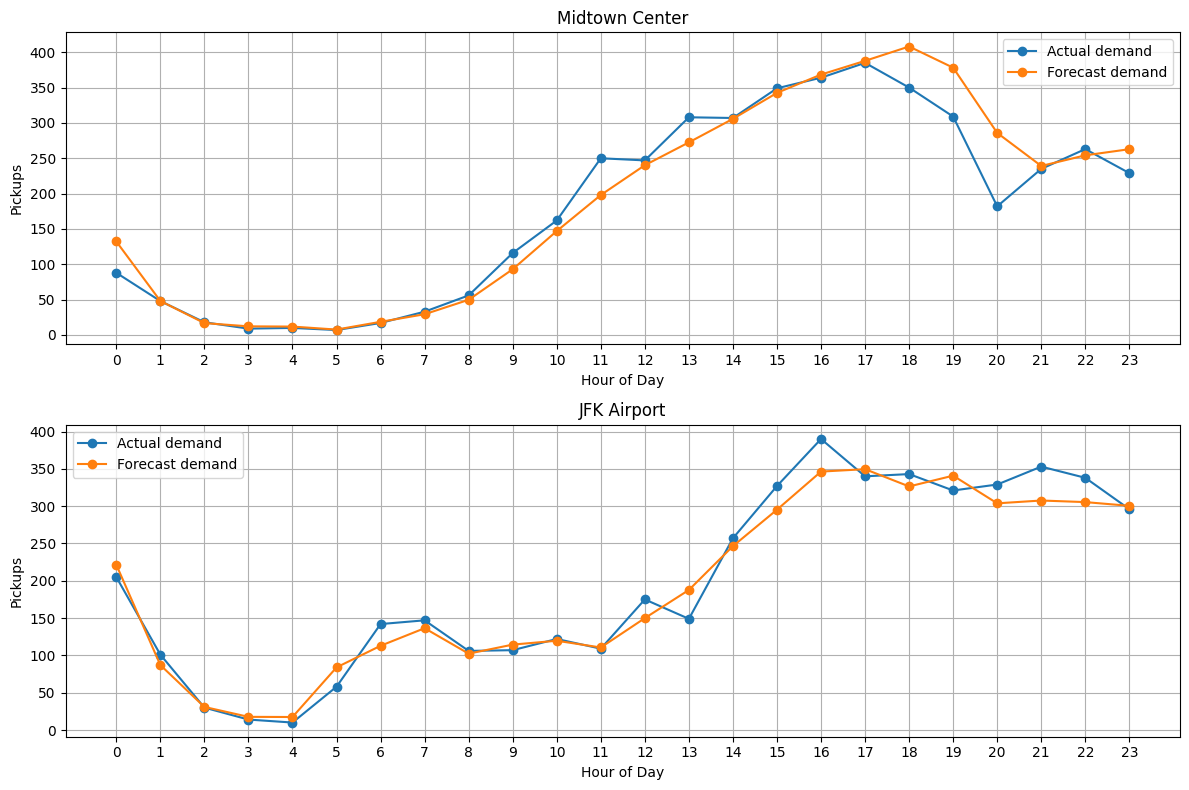

In [47]:
# RIDESMART - 24-HOUR FORECAST VISUALISATION

import matplotlib.pyplot as plt

selected_date = pd.Timestamp("2025-03-15").date()

selected_zones = [
    "Midtown Center",
    "JFK Airport"
]

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

for ax, zone in zip(axes, selected_zones):

    data = forecast_24h[
        (forecast_24h["pickup_date"] == selected_date) &
        (forecast_24h["Zone"] == zone)
    ]

    ax.plot(
        data["pickup_hour"],
        data["actual"],
        marker="o",
        label="Actual demand"
    )

    ax.plot(
        data["pickup_hour"],
        data["predicted"],
        marker="o",
        label="Forecast demand"
    )

    ax.set_title(zone)
    ax.set_xlabel("Hour of Day")
    ax.set_ylabel("Pickups")
    ax.set_xticks(range(24))
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

In [48]:
# RIDESMART - OVERALL 24-HOUR FORECAST METRICS

actual = forecast_24h["actual"]
predicted = forecast_24h["predicted"]

print("24-HOUR FORECAST PERFORMANCE")
print("----------------------------")
print("MAE:", round(mean_absolute_error(actual, predicted), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(actual, predicted)), 3))
print("R2:", round(r2_score(actual, predicted), 3))

24-HOUR FORECAST PERFORMANCE
----------------------------
MAE: 28.081
RMSE: 43.879
R2: 0.91


In [49]:
# RIDESMART - 24-HOUR PERFORMANCE BY ZONE

zone_24h_results = (
    forecast_24h.groupby("Zone")
    .apply(
        lambda group: pd.Series({
            "MAE": mean_absolute_error(
                group["actual"], group["predicted"]
            ),
            "RMSE": np.sqrt(mean_squared_error(
                group["actual"], group["predicted"]
            )),
            "R2": r2_score(
                group["actual"], group["predicted"]
            )
        }),
        include_groups=False
    )
    .reset_index()
)

display(zone_24h_results.round(3))

,Zone,MAE,RMSE,R2
0,JFK Airport,39.286,57.615,0.812
1,Lincoln Square East,25.969,45.012,0.856
2,Midtown Center,31.425,51.681,0.940
3,Midtown East,22.337,34.728,0.934
4,Murray Hill,20.328,28.769,0.921
5,Penn Station/Madison Sq West,32.998,48.446,0.781
6,Times Sq/Theatre District,29.102,41.697,0.909
7,Union Sq,21.536,33.195,0.923
8,Upper East Side North,30.257,47.099,0.913
9,Upper East Side South,27.569,42.399,0.939


In [50]:
# RIDESMART - 24-HOUR BASELINE COMPARISON

baseline_predictions = forecast_24h.apply(
    lambda row: actual_lookup[
        (
            row["pickup_date"] - timedelta(days=7),
            row["Zone"],
            row["pickup_hour"]
        )
    ],
    axis=1
)

actual = forecast_24h["actual"]
predicted = forecast_24h["predicted"]

comparison_24h = pd.DataFrame({
    "Model": [
        "Previous Week Baseline",
        "Random Forest 24-Hour"
    ],
    "MAE": [
        mean_absolute_error(actual, baseline_predictions),
        mean_absolute_error(actual, predicted)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(actual, baseline_predictions)),
        np.sqrt(mean_squared_error(actual, predicted))
    ],
    "R2": [
        r2_score(actual, baseline_predictions),
        r2_score(actual, predicted)
    ]
})

display(comparison_24h.round(3))

,Model,MAE,RMSE,R2
0,Previous Week Baseline,30.528,48.263,0.891
1,Random Forest 24-Hour,28.081,43.879,0.910


Select a forecast date

In [51]:
# RIDESMART - VEHICLE ALLOCATION INPUT

selected_date = pd.Timestamp("2025-03-15").date()

fleet_size = 500

allocation_input = forecast_24h[
    forecast_24h["pickup_date"] == selected_date
].copy()

print("Selected date:", selected_date)
print("Total forecast records:", len(allocation_input))
print("Available simulated vehicles:", fleet_size)

display(
    allocation_input[
        ["Zone", "pickup_hour", "predicted"]
    ].head(10)
)

Selected date: 2025-03-15
Total forecast records: 240
Available simulated vehicles: 500


,Zone,pickup_hour,predicted
3360,Midtown Center,0,132.282416
3361,Midtown Center,1,48.152643
3362,Midtown Center,2,16.834168
3363,Midtown Center,3,12.225177
3364,Midtown Center,4,11.895276
3365,Midtown Center,5,7.669456
3366,Midtown Center,6,18.628178
3367,Midtown Center,7,29.364380
3368,Midtown Center,8,49.797705
3369,Midtown Center,9,93.021047


Allocate vehicles by predicted demand

In [52]:
# RIDESMART - HOURLY VEHICLE ALLOCATION

def allocate_vehicles(hour_data, total_fleet):

    hour_data = hour_data.copy()

    total_demand = hour_data["predicted"].sum()

    # Calculate each zone's proportional vehicle allocation
    hour_data["exact_allocation"] = (
        hour_data["predicted"] / total_demand
    ) * total_fleet

    # Initial whole-number allocation
    hour_data["allocated_vehicles"] = (
        np.floor(hour_data["exact_allocation"]).astype(int)
    )

    # Distribute remaining vehicles using largest remainders
    remaining = (
        total_fleet -
        hour_data["allocated_vehicles"].sum()
    )

    hour_data["remainder"] = (
        hour_data["exact_allocation"] -
        hour_data["allocated_vehicles"]
    )

    hour_data = hour_data.sort_values(
        "remainder",
        ascending=False
    )

    hour_data.loc[
        hour_data.index[:remaining],
        "allocated_vehicles"
    ] += 1

    return hour_data


# Demonstrate allocation at 6 PM
hour_18 = allocation_input[
    allocation_input["pickup_hour"] == 18
].copy()

allocation_18 = allocate_vehicles(
    hour_18,
    fleet_size
)

allocation_18 = allocation_18.sort_values(
    "allocated_vehicles",
    ascending=False
)

display(
    allocation_18[
        ["Zone", "predicted", "allocated_vehicles"]
    ]
)

print(
    "Total allocated vehicles:",
    allocation_18["allocated_vehicles"].sum()
)

,Zone,predicted,allocated_vehicles
3402,Upper East Side South,438.884590,67
3426,Upper East Side North,429.615803,65
3378,Midtown Center,408.121649,62
3450,JFK Airport,326.436543,50
3546,Lincoln Square East,301.255078,46
3522,Midtown East,293.455734,45
3474,Times Sq/Theatre District,285.326928,43
3498,Penn Station/Madison Sq West,273.401969,42
3570,Union Sq,269.020343,41
3594,Murray Hill,258.304356,39


Total allocated vehicles: 500


build the complete 24-hour allocation schedule

In [53]:
# RIDESMART - FULL 24-HOUR VEHICLE ALLOCATION

allocation_schedule = []

for hour in range(24):

    hour_data = allocation_input[
        allocation_input["pickup_hour"] == hour
    ].copy()

    hourly_allocation = allocate_vehicles(
        hour_data,
        fleet_size
    )

    hourly_allocation["pickup_hour"] = hour

    allocation_schedule.append(
        hourly_allocation[
            [
                "Zone",
                "pickup_hour",
                "predicted",
                "allocated_vehicles"
            ]
        ]
    )

allocation_schedule = pd.concat(
    allocation_schedule,
    ignore_index=True
)

print("Schedule shape:", allocation_schedule.shape)

# Verify that exactly 500 vehicles are allocated each hour
hourly_totals = (
    allocation_schedule
    .groupby("pickup_hour")["allocated_vehicles"]
    .sum()
)

display(hourly_totals)

print(
    "All hours allocate exactly 500:",
    (hourly_totals == fleet_size).all()
)

Schedule shape: (240, 4)


,allocated_vehicles
pickup_hour,
0,500
1,500
2,500
3,500
4,500
5,500
6,500
7,500
8,500


All hours allocate exactly 500: True


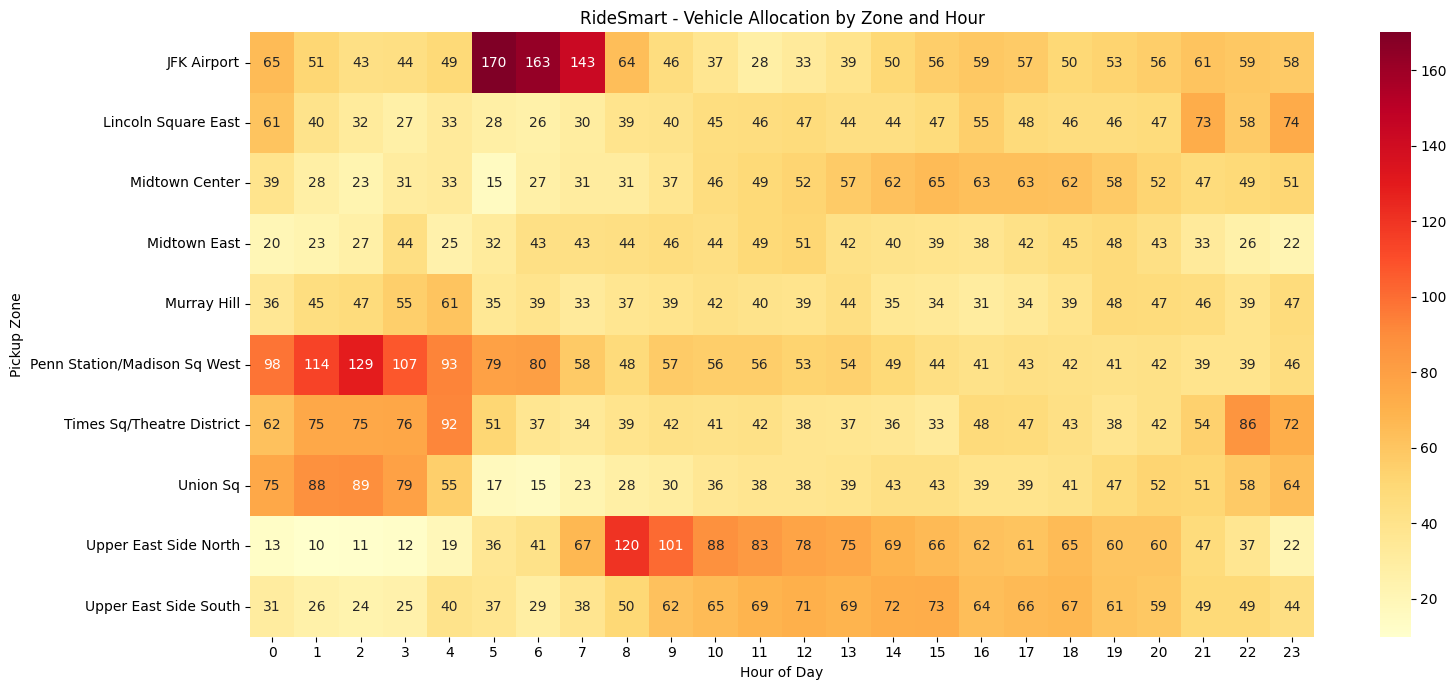

In [54]:
# RIDESMART - VEHICLE ALLOCATION HEATMAP

allocation_heatmap = allocation_schedule.pivot(
    index="Zone",
    columns="pickup_hour",
    values="allocated_vehicles"
)

plt.figure(figsize=(16, 7))

sns.heatmap(
    allocation_heatmap,
    cmap="YlOrRd",
    annot=True,
    fmt=".0f"
)

plt.title("RideSmart - Vehicle Allocation by Zone and Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Pickup Zone")
plt.tight_layout()
plt.show()

calculate vehicle service capacity

In [55]:
# RIDESMART - TRIP DURATION ANALYSIS

# Keep only January-March 2025 pickups
duration_data = trips[
    (trips["tpep_pickup_datetime"] >= "2025-01-01") &
    (trips["tpep_pickup_datetime"] < "2025-04-01") &
    (trips["trip_duration_min"] > 0)
][
    ["PULocationID", "trip_duration_min"]
].copy()

# Attach taxi zone names
duration_data = duration_data.merge(
    zones[["LocationID", "Zone"]],
    left_on="PULocationID",
    right_on="LocationID",
    how="inner"
)

# Keep our ten selected zones
duration_data = duration_data[
    duration_data["Zone"].isin(top_10_train_zones)
]

# Calculate duration statistics
duration_summary = (
    duration_data
    .groupby("Zone")["trip_duration_min"]
    .agg(
        trip_count="count",
        average_duration="mean",
        median_duration="median",
        p75_duration=lambda x: x.quantile(0.75),
        p90_duration=lambda x: x.quantile(0.90)
    )
    .reset_index()
)

display(duration_summary.round(2))

,Zone,trip_count,average_duration,median_duration,p75_duration,p90_duration
0,JFK Airport,432892,39.29,38.73,50.85,62.53
1,Lincoln Square East,331160,12.56,10.33,15.17,21.60
2,Midtown Center,511897,14.45,12.17,17.38,23.88
3,Midtown East,359585,13.84,11.80,17.08,23.10
4,Murray Hill,302666,13.46,11.50,16.50,22.35
5,Penn Station/Madison Sq West,364813,15.06,12.95,18.98,25.70
6,Times Sq/Theatre District,376362,15.46,12.25,18.58,27.33
7,Union Sq,311974,13.04,10.92,16.20,22.28
8,Upper East Side North,454765,12.01,9.50,14.93,22.32
9,Upper East Side South,489954,11.63,9.17,14.30,21.28


trip durations

In [56]:
# RIDESMART - VALIDATE TRIP DURATIONS

duration_check = (
    duration_data.groupby("Zone")["trip_duration_min"]
    .agg(
        trip_count="count",
        median="median",
        p90=lambda x: x.quantile(0.90),
        p95=lambda x: x.quantile(0.95),
        maximum="max",
        over_2_hours=lambda x: (x > 120).sum(),
        over_24_hours=lambda x: (x > 1440).sum()
    )
    .reset_index()
)

display(duration_check.round(2))

,Zone,trip_count,median,p90,p95,maximum,over_2_hours,over_24_hours
0,JFK Airport,432892,38.73,62.53,70.22,8564.67,711,7
1,Lincoln Square East,331160,10.33,21.60,26.87,1439.40,136,0
2,Midtown Center,511897,12.17,23.88,29.27,6275.83,209,3
3,Midtown East,359585,11.80,23.10,27.92,3262.48,152,1
4,Murray Hill,302666,11.50,22.35,27.25,1556.43,124,1
5,Penn Station/Madison Sq West,364813,12.95,25.70,30.67,1824.58,150,1
6,Times Sq/Theatre District,376362,12.25,27.33,34.67,5451.43,206,2
7,Union Sq,311974,10.92,22.28,26.68,1439.05,126,0
8,Upper East Side North,454765,9.50,22.32,27.23,1438.48,143,0
9,Upper East Side South,489954,9.17,21.28,26.02,1439.17,172,0


Calculate cleaned trip-duration statistics

In [57]:
# RIDESMART - CLEANED TRIP DURATION STATISTICS

duration_clean = duration_data[
    (duration_data["trip_duration_min"] > 0) &
    (duration_data["trip_duration_min"] <= 120)
].copy()

clean_duration_summary = (
    duration_clean
    .groupby("Zone")["trip_duration_min"]
    .agg(
        valid_trips="count",
        average_duration="mean",
        median_duration="median",
        p90_duration=lambda x: x.quantile(0.90)
    )
    .reset_index()
)

display(clean_duration_summary.round(2))

print("Original duration records:", len(duration_data))
print("Records after filtering:", len(duration_clean))
print("Records excluded:", len(duration_data) - len(duration_clean))

,Zone,valid_trips,average_duration,median_duration,p90_duration
0,JFK Airport,432181,38.52,38.70,62.38
1,Lincoln Square East,331024,12.11,10.33,21.57
2,Midtown Center,511688,13.98,12.15,23.87
3,Midtown East,359433,13.42,11.80,23.07
4,Murray Hill,302542,13.04,11.48,22.32
5,Penn Station/Madison Sq West,364663,14.68,12.95,25.67
6,Times Sq/Theatre District,376156,14.96,12.25,27.28
7,Union Sq,311848,12.60,10.92,22.27
8,Upper East Side North,454622,11.63,9.50,22.30
9,Upper East Side South,489782,11.23,9.17,21.25


Original duration records: 3936068
Records after filtering: 3933939
Records excluded: 2129


Combine demand and trip duration

In [58]:
# RIDESMART - VEHICLE CAPACITY MODEL

target_utilisation = 0.85
fleet_size = 500

# Select the demonstration date
selected_date = pd.Timestamp("2025-03-15").date()

capacity_data = forecast_24h[
    forecast_24h["pickup_date"] == selected_date
].copy()

# Attach cleaned average trip durations
capacity_data = capacity_data.merge(
    clean_duration_summary[
        ["Zone", "average_duration"]
    ],
    on="Zone",
    how="left",
    validate="many_to_one"
)

# Estimate required vehicles
capacity_data["required_vehicles"] = (
    capacity_data["predicted"] *
    capacity_data["average_duration"]
) / (60 * target_utilisation)

print("Missing duration values:",
      capacity_data["average_duration"].isna().sum())

display(
    capacity_data[
        ["Zone", "pickup_hour", "predicted",
         "average_duration", "required_vehicles"]
    ].head(10).round(2)
)

Missing duration values: 0


,Zone,pickup_hour,predicted,average_duration,required_vehicles
0,Midtown Center,0,132.28,13.98,36.27
1,Midtown Center,1,48.15,13.98,13.20
2,Midtown Center,2,16.83,13.98,4.62
3,Midtown Center,3,12.23,13.98,3.35
4,Midtown Center,4,11.90,13.98,3.26
5,Midtown Center,5,7.67,13.98,2.10
6,Midtown Center,6,18.63,13.98,5.11
7,Midtown Center,7,29.36,13.98,8.05
8,Midtown Center,8,49.80,13.98,13.65
9,Midtown Center,9,93.02,13.98,25.50


Calculate the 6 PM allocation

In [59]:
# RIDESMART - CAPACITY-AWARE ALLOCATION AT 6 PM

hour_capacity = capacity_data[
    capacity_data["pickup_hour"] == 18
].copy()

total_required = hour_capacity["required_vehicles"].sum()

if total_required <= fleet_size:
    hour_capacity["allocated_vehicles"] = (
        np.floor(hour_capacity["required_vehicles"]).astype(int)
    )

    remaining = (
        fleet_size -
        hour_capacity["allocated_vehicles"].sum()
    )

    hour_capacity["remainder"] = (
        hour_capacity["required_vehicles"] -
        hour_capacity["allocated_vehicles"]
    )

    hour_capacity = hour_capacity.sort_values(
        "remainder", ascending=False
    )

    hour_capacity.loc[
        hour_capacity.index[:remaining],
        "allocated_vehicles"
    ] += 1

else:
    # Scale requirements to the available fleet
    hour_capacity["exact_allocation"] = (
        hour_capacity["required_vehicles"] /
        total_required
    ) * fleet_size

    hour_capacity["allocated_vehicles"] = (
        np.floor(hour_capacity["exact_allocation"]).astype(int)
    )

    remaining = (
        fleet_size -
        hour_capacity["allocated_vehicles"].sum()
    )

    hour_capacity["remainder"] = (
        hour_capacity["exact_allocation"] -
        hour_capacity["allocated_vehicles"]
    )

    hour_capacity = hour_capacity.sort_values(
        "remainder", ascending=False
    )

    hour_capacity.loc[
        hour_capacity.index[:remaining],
        "allocated_vehicles"
    ] += 1

# Estimate hourly service capacity
hour_capacity["service_capacity"] = (
    hour_capacity["allocated_vehicles"] *
    60 * target_utilisation /
    hour_capacity["average_duration"]
)

hour_capacity["unserved_demand"] = (
    hour_capacity["predicted"] -
    hour_capacity["service_capacity"]
).clip(lower=0)

display(
    hour_capacity[
        ["Zone", "predicted", "average_duration",
         "required_vehicles", "allocated_vehicles",
         "service_capacity", "unserved_demand"]
    ].round(2)
)

print("Total required vehicles:", round(total_required, 2))
print("Total allocated vehicles:",
      hour_capacity["allocated_vehicles"].sum())
print("Total predicted demand:",
      round(hour_capacity["predicted"].sum(), 2))
print("Estimated unserved demand:",
      round(hour_capacity["unserved_demand"].sum(), 2))

,Zone,predicted,average_duration,required_vehicles,allocated_vehicles,service_capacity,unserved_demand
114,Times Sq/Theatre District,285.33,14.96,83.69,42,143.19,142.13
186,Lincoln Square East,301.26,12.11,71.53,36,151.61,149.65
162,Midtown East,293.46,13.42,77.23,39,148.19,145.27
90,JFK Airport,326.44,38.52,246.53,124,164.19,162.24
138,Penn Station/Madison Sq West,273.40,14.68,78.71,40,138.93,134.47
42,Upper East Side South,438.88,11.23,96.61,48,218.06,220.82
210,Union Sq,269.02,12.60,66.48,33,133.54,135.48
66,Upper East Side North,429.62,11.63,97.97,49,214.88,214.74
234,Murray Hill,258.30,13.04,66.07,33,129.02,129.28
18,Midtown Center,408.12,13.98,111.89,56,204.27,203.85


Total required vehicles: 996.71
Total allocated vehicles: 500
Total predicted demand: 3283.82
Estimated unserved demand: 1637.94


capacity-aware allocation for all 24 hours

In [60]:
# RIDESMART - CAPACITY-AWARE 24-HOUR ALLOCATION

def capacity_aware_allocation(hour_data, fleet_size=500,
                              utilisation=0.85):

    hour_data = hour_data.copy()

    # Estimate required vehicles per zone
    hour_data["required_vehicles"] = (
        hour_data["predicted"] *
        hour_data["average_duration"]
    ) / (60 * utilisation)

    total_required = hour_data["required_vehicles"].sum()

    # Allocate no more than the available fleet
    allocation_target = min(
        fleet_size,
        round(total_required)
    )

    # Distribute vehicles proportionally to requirements
    if total_required > 0:
        exact = (
            hour_data["required_vehicles"] /
            total_required
        ) * allocation_target
    else:
        exact = pd.Series(0, index=hour_data.index)

    hour_data["allocated_vehicles"] = np.floor(
        exact
    ).astype(int)

    remaining = (
        allocation_target -
        hour_data["allocated_vehicles"].sum()
    )

    remainders = exact - hour_data["allocated_vehicles"]

    winners = remainders.nlargest(remaining).index

    hour_data.loc[winners, "allocated_vehicles"] += 1

    # Calculate service capacity and unmet demand
    hour_data["service_capacity"] = (
        hour_data["allocated_vehicles"] *
        60 * utilisation /
        hour_data["average_duration"]
    )

    hour_data["unserved_demand"] = (
        hour_data["predicted"] -
        hour_data["service_capacity"]
    ).clip(lower=0)

    return hour_data


# Generate allocation for all 24 hours
capacity_schedule = []

for hour in range(24):

    hour_data = capacity_data[
        capacity_data["pickup_hour"] == hour
    ].copy()

    result = capacity_aware_allocation(
        hour_data,
        fleet_size=500,
        utilisation=0.85
    )

    result["pickup_hour"] = hour

    capacity_schedule.append(result)

capacity_schedule = pd.concat(
    capacity_schedule,
    ignore_index=True
)

print("Capacity schedule:", capacity_schedule.shape)

display(
    capacity_schedule[
        [
            "Zone",
            "pickup_hour",
            "predicted",
            "required_vehicles",
            "allocated_vehicles",
            "service_capacity",
            "unserved_demand"
        ]
    ].head(15).round(2)
)

Capacity schedule: (240, 10)


,Zone,pickup_hour,predicted,required_vehicles,allocated_vehicles,service_capacity,unserved_demand
0,Midtown Center,0,132.28,36.27,33,120.37,11.91
1,Upper East Side South,0,103.36,22.75,21,95.40,7.96
2,Upper East Side North,0,43.08,9.82,9,39.47,3.61
3,JFK Airport,0,221.43,167.23,151,199.94,21.49
4,Times Sq/Theatre District,0,210.70,61.80,56,190.93,19.77
5,Penn Station/Madison Sq West,0,331.49,95.44,86,298.71,32.78
6,Midtown East,0,66.48,17.50,16,60.80,5.69
7,Lincoln Square East,0,204.70,48.61,44,185.30,19.40
8,Union Sq,0,252.12,62.30,56,226.61,25.51
9,Murray Hill,0,123.51,31.59,28,109.47,14.03


hourly operational summary

In [61]:
# RIDESMART - HOURLY FLEET PERFORMANCE

hourly_summary = (
    capacity_schedule
    .groupby("pickup_hour")
    .agg(
        predicted_demand=("predicted", "sum"),
        required_vehicles=("required_vehicles", "sum"),
        allocated_vehicles=("allocated_vehicles", "sum"),
        service_capacity=("service_capacity", "sum"),
        unserved_demand=("unserved_demand", "sum")
    )
    .reset_index()
)

hourly_summary["demand_coverage_pct"] = (
    hourly_summary["service_capacity"] /
    hourly_summary["predicted_demand"] * 100
)

display(hourly_summary.round(2))

,pickup_hour,predicted_demand,required_vehicles,allocated_vehicles,service_capacity,unserved_demand,demand_coverage_pct
0,0,1689.15,553.30,500,1526.99,162.15,90.40
1,1,852.86,269.25,269,851.23,5.70,99.81
2,2,361.60,111.58,112,363.95,3.06,100.65
3,3,199.77,61.83,62,201.46,4.28,100.84
4,4,178.04,55.73,56,179.83,4.82,101.01
5,5,247.41,106.18,106,247.38,4.26,99.99
6,6,346.80,146.45,146,345.37,6.25,99.59
7,7,478.65,190.62,191,480.14,3.03,100.31
8,8,795.34,251.07,251,795.71,3.92,100.05
9,9,1244.83,371.57,372,1245.19,4.97,100.03


In [62]:
# RIDESMART - CORRECTED SERVICE METRICS

hourly_summary["served_demand"] = np.minimum(
    hourly_summary["predicted_demand"],
    hourly_summary["service_capacity"]
)

hourly_summary["unserved_demand"] = (
    hourly_summary["predicted_demand"] -
    hourly_summary["served_demand"]
).clip(lower=0)

hourly_summary["demand_coverage_pct"] = (
    hourly_summary["served_demand"] /
    hourly_summary["predicted_demand"] * 100
).fillna(0).clip(0, 100)

display(hourly_summary.round(2))

,pickup_hour,predicted_demand,required_vehicles,allocated_vehicles,service_capacity,unserved_demand,demand_coverage_pct,served_demand
0,0,1689.15,553.30,500,1526.99,162.15,90.40,1526.99
1,1,852.86,269.25,269,851.23,1.63,99.81,851.23
2,2,361.60,111.58,112,363.95,0.00,100.00,361.60
3,3,199.77,61.83,62,201.46,0.00,100.00,199.77
4,4,178.04,55.73,56,179.83,0.00,100.00,178.04
5,5,247.41,106.18,106,247.38,0.02,99.99,247.38
6,6,346.80,146.45,146,345.37,1.43,99.59,345.37
7,7,478.65,190.62,191,480.14,0.00,100.00,478.65
8,8,795.34,251.07,251,795.71,0.00,100.00,795.34
9,9,1244.83,371.57,372,1245.19,0.00,100.00,1244.83


Fleet requirement versus availability

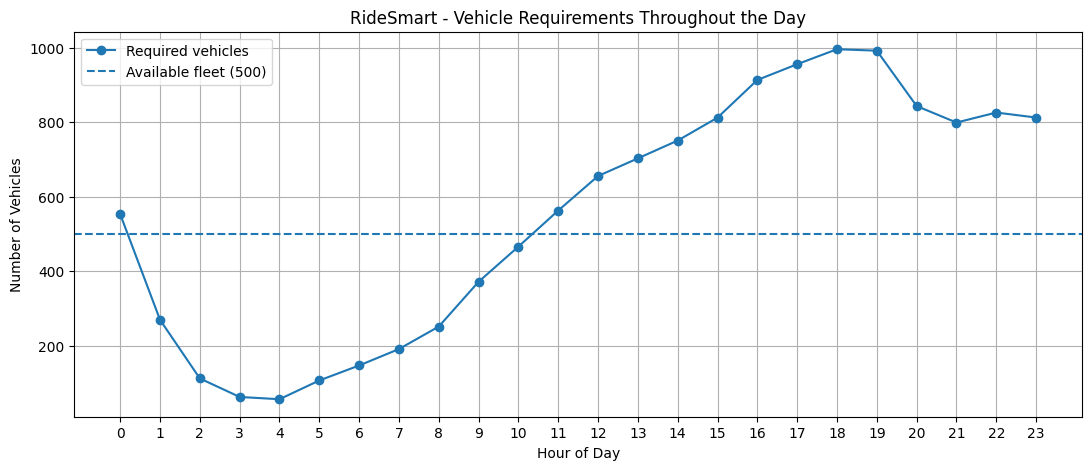

In [63]:
plt.figure(figsize=(13, 5))

plt.plot(
    hourly_summary["pickup_hour"],
    hourly_summary["required_vehicles"],
    marker="o",
    label="Required vehicles"
)

plt.axhline(
    y=500,
    linestyle="--",
    label="Available fleet (500)"
)

plt.title("RideSmart - Vehicle Requirements Throughout the Day")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Vehicles")
plt.xticks(range(24))
plt.legend()
plt.grid(True)
plt.show()

Demand coverage throughout the day

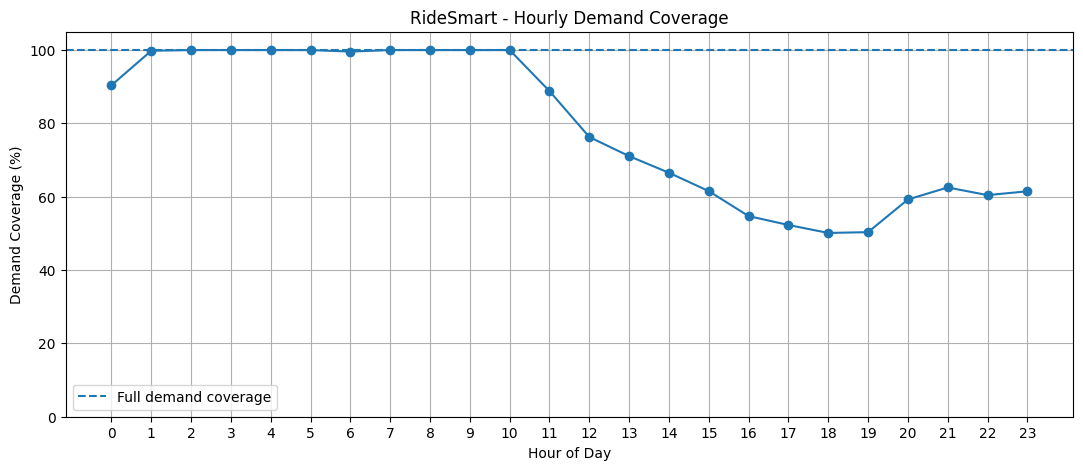

In [64]:
plt.figure(figsize=(13, 5))

plt.plot(
    hourly_summary["pickup_hour"],
    hourly_summary["demand_coverage_pct"],
    marker="o"
)

plt.axhline(
    y=100,
    linestyle="--",
    label="Full demand coverage"
)

plt.title("RideSmart - Hourly Demand Coverage")
plt.xlabel("Hour of Day")
plt.ylabel("Demand Coverage (%)")
plt.xticks(range(24))
plt.ylim(0, 105)
plt.legend()
plt.grid(True)
plt.show()

zone-level fleet allocation model

In [65]:
print(capacity_data.columns.tolist())
print(capacity_data.head())

['pickup_date', 'Zone', 'pickup_hour', 'actual', 'predicted', 'average_duration', 'required_vehicles']
  pickup_date            Zone  pickup_hour  actual   predicted  \
0  2025-03-15  Midtown Center            0      88  132.282416   
1  2025-03-15  Midtown Center            1      48   48.152643   
2  2025-03-15  Midtown Center            2      18   16.834168   
3  2025-03-15  Midtown Center            3       9   12.225177   
4  2025-03-15  Midtown Center            4      10   11.895276   

   average_duration  required_vehicles  
0         13.981597          36.265086  
1         13.981597          13.200997  
2         13.981597           4.615070  
3         13.981597           3.351520  
4         13.981597           3.261078  


Allocate 500 vehicles across the 10 zones

In [66]:
import numpy as np
import pandas as pd

def allocate_fleet(hour_data, fleet_size=500):

    hour_data = hour_data.copy()

    total_required = hour_data["required_vehicles"].sum()

    if total_required <= 0:
        hour_data["allocated_vehicles"] = 0
        return hour_data

    # Calculate proportional allocation
    exact_allocation = (
        hour_data["required_vehicles"] / total_required
    ) * fleet_size

    # Take whole-number allocations first
    hour_data["allocated_vehicles"] = np.floor(
        exact_allocation
    ).astype(int)

    # Distribute remaining vehicles by largest decimal remainder
    remaining = fleet_size - hour_data["allocated_vehicles"].sum()

    remainders = exact_allocation - np.floor(exact_allocation)

    priority = remainders.sort_values(ascending=False).index[:remaining]

    hour_data.loc[priority, "allocated_vehicles"] += 1

    return hour_data

Test it for 6 PM on March 15

In [67]:
test_hour = capacity_data[
    (capacity_data["pickup_date"] == "2025-03-15") &
    (capacity_data["pickup_hour"] == 18)
].copy()

allocation_6pm = allocate_fleet(test_hour, fleet_size=500)

display(
    allocation_6pm[
        ["Zone", "predicted", "required_vehicles", "allocated_vehicles"]
    ].sort_values("allocated_vehicles", ascending=False).round(2)
)

print("Total vehicles allocated:",
      allocation_6pm["allocated_vehicles"].sum())

,Zone,predicted,required_vehicles,allocated_vehicles


Total vehicles allocated: 0


In [68]:
print("Date column type:", capacity_data["pickup_date"].dtype)
print("Available dates:")
print(capacity_data["pickup_date"].unique()[:10])

print("\nAvailable hours:")
print(sorted(capacity_data["pickup_hour"].unique()))

print("\nRows in capacity_data:", len(capacity_data))

Date column type: object
Available dates:
[datetime.date(2025, 3, 15)]

Available hours:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23)]

Rows in capacity_data: 240


In [69]:
capacity_data["pickup_date"] = pd.to_datetime(
    capacity_data["pickup_date"]
).dt.normalize()

test_hour = capacity_data[
    (capacity_data["pickup_date"] == pd.Timestamp("2025-03-15")) &
    (capacity_data["pickup_hour"] == 18)
].copy()

print("Rows selected:", len(test_hour))
display(test_hour.head())

Rows selected: 10


,pickup_date,Zone,pickup_hour,actual,predicted,average_duration,required_vehicles
18,2025-03-15,Midtown Center,18,350,408.121649,13.981597,111.886123
42,2025-03-15,Upper East Side South,18,437,438.884590,11.226283,96.608677
66,2025-03-15,Upper East Side North,18,374,429.615803,11.629890,97.968322
90,2025-03-15,JFK Airport,18,343,326.436543,38.515704,246.528101
114,2025-03-15,Times Sq/Theatre District,18,251,285.326928,14.958656,83.688381


In [70]:
allocation_6pm = allocate_fleet(test_hour, fleet_size=500)

display(
    allocation_6pm[
        ["Zone", "predicted", "required_vehicles", "allocated_vehicles"]
    ].sort_values(
        "allocated_vehicles", ascending=False
    ).round(2)
)

print("Total vehicles allocated:",
      allocation_6pm["allocated_vehicles"].sum())

,Zone,predicted,required_vehicles,allocated_vehicles
90,JFK Airport,326.44,246.53,124
18,Midtown Center,408.12,111.89,56
66,Upper East Side North,429.62,97.97,49
42,Upper East Side South,438.88,96.61,48
114,Times Sq/Theatre District,285.33,83.69,42
138,Penn Station/Madison Sq West,273.40,78.71,40
162,Midtown East,293.46,77.23,39
186,Lincoln Square East,301.26,71.53,36
210,Union Sq,269.02,66.48,33
234,Murray Hill,258.30,66.07,33


Total vehicles allocated: 500


calculate service capacity and unmet demand

In [71]:
allocation_6pm["service_capacity"] = (
    allocation_6pm["allocated_vehicles"] *
    60 * 0.85 /
    allocation_6pm["average_duration"]
)

allocation_6pm["served_demand"] = np.minimum(
    allocation_6pm["predicted"],
    allocation_6pm["service_capacity"]
)

allocation_6pm["unserved_demand"] = (
    allocation_6pm["predicted"] -
    allocation_6pm["served_demand"]
).clip(lower=0)

allocation_6pm["coverage_pct"] = (
    allocation_6pm["served_demand"] /
    allocation_6pm["predicted"] * 100
)

display(
    allocation_6pm[
        [
            "Zone",
            "predicted",
            "allocated_vehicles",
            "service_capacity",
            "served_demand",
            "unserved_demand",
            "coverage_pct"
        ]
    ].round(2)
)

,Zone,predicted,allocated_vehicles,service_capacity,served_demand,unserved_demand,coverage_pct
18,Midtown Center,408.12,56,204.27,204.27,203.85,50.05
42,Upper East Side South,438.88,48,218.06,218.06,220.82,49.68
66,Upper East Side North,429.62,49,214.88,214.88,214.74,50.02
90,JFK Airport,326.44,124,164.19,164.19,162.24,50.30
114,Times Sq/Theatre District,285.33,42,143.19,143.19,142.13,50.19
138,Penn Station/Madison Sq West,273.40,40,138.93,138.93,134.47,50.82
162,Midtown East,293.46,39,148.19,148.19,145.27,50.50
186,Lincoln Square East,301.26,36,151.61,151.61,149.65,50.33
210,Union Sq,269.02,33,133.54,133.54,135.48,49.64
234,Murray Hill,258.30,33,129.02,129.02,129.28,49.95


identify zones with the biggest shortages

In [72]:
# Overall fleet performance
total_demand = allocation_6pm["predicted"].sum()
total_served = allocation_6pm["served_demand"].sum()
total_unserved = allocation_6pm["unserved_demand"].sum()

overall_coverage = (total_served / total_demand) * 100

print("TOTAL PREDICTED DEMAND:", round(total_demand, 2))
print("TOTAL SERVED DEMAND:", round(total_served, 2))
print("TOTAL UNSERVED DEMAND:", round(total_unserved, 2))
print("OVERALL COVERAGE:", round(overall_coverage, 2), "%")

# Rank zones by unserved demand
zone_shortages = allocation_6pm[
    ["Zone", "predicted", "allocated_vehicles",
     "served_demand", "unserved_demand", "coverage_pct"]
].sort_values("unserved_demand", ascending=False)

display(zone_shortages.round(2))

TOTAL PREDICTED DEMAND: 3283.82
TOTAL SERVED DEMAND: 1645.88
TOTAL UNSERVED DEMAND: 1637.94
OVERALL COVERAGE: 50.12 %


,Zone,predicted,allocated_vehicles,served_demand,unserved_demand,coverage_pct
42,Upper East Side South,438.88,48,218.06,220.82,49.68
66,Upper East Side North,429.62,49,214.88,214.74,50.02
18,Midtown Center,408.12,56,204.27,203.85,50.05
90,JFK Airport,326.44,124,164.19,162.24,50.30
186,Lincoln Square East,301.26,36,151.61,149.65,50.33
162,Midtown East,293.46,39,148.19,145.27,50.50
114,Times Sq/Theatre District,285.33,42,143.19,142.13,50.19
210,Union Sq,269.02,33,133.54,135.48,49.64
138,Penn Station/Madison Sq West,273.40,40,138.93,134.47,50.82
234,Murray Hill,258.30,33,129.02,129.28,49.95


Build demand-priority allocation

In [73]:
priority_allocation = allocation_6pm.copy()

# Allocate vehicles according to predicted demand
exact_vehicles = (
    priority_allocation["predicted"] /
    priority_allocation["predicted"].sum()
) * 500

priority_allocation["priority_vehicles"] = np.floor(
    exact_vehicles
).astype(int)

# Distribute remaining vehicles
remaining = 500 - priority_allocation["priority_vehicles"].sum()

remainders = exact_vehicles - np.floor(exact_vehicles)

priority_indices = remainders.sort_values(
    ascending=False
).index[:remaining]

priority_allocation.loc[
    priority_indices, "priority_vehicles"
] += 1

# Calculate service capacity
priority_allocation["priority_capacity"] = (
    priority_allocation["priority_vehicles"] *
    60 * 0.85 /
    priority_allocation["average_duration"]
)

priority_allocation["priority_served"] = np.minimum(
    priority_allocation["predicted"],
    priority_allocation["priority_capacity"]
)

priority_allocation["priority_unserved"] = (
    priority_allocation["predicted"] -
    priority_allocation["priority_served"]
).clip(lower=0)

display(
    priority_allocation[
        ["Zone", "predicted", "priority_vehicles",
         "priority_served", "priority_unserved"]
    ].sort_values("priority_vehicles", ascending=False).round(2)
)

print("Total priority vehicles:",
      priority_allocation["priority_vehicles"].sum())

print("Total priority demand served:",
      round(priority_allocation["priority_served"].sum(), 2))

,Zone,predicted,priority_vehicles,priority_served,priority_unserved
42,Upper East Side South,438.88,67,304.38,134.51
66,Upper East Side North,429.62,65,285.04,144.57
18,Midtown Center,408.12,62,226.15,181.97
90,JFK Airport,326.44,50,66.21,260.23
186,Lincoln Square East,301.26,46,193.72,107.53
162,Midtown East,293.46,45,170.99,122.47
114,Times Sq/Theatre District,285.33,43,146.60,138.72
138,Penn Station/Madison Sq West,273.40,42,145.88,127.52
210,Union Sq,269.02,41,165.91,103.11
234,Murray Hill,258.30,39,152.48,105.83


Total priority vehicles: 500
Total priority demand served: 1857.36


test both strategies across all 24 hours

In [74]:
def allocate_by_strategy(hour_data, fleet_size=500, strategy="proportional"):

    data = hour_data.copy()

    if strategy == "proportional":
        weights = data["required_vehicles"].clip(lower=0)

    elif strategy == "priority":
        weights = data["predicted"].clip(lower=0)

    else:
        raise ValueError("Unknown strategy")

    total_required = data["required_vehicles"].sum()

    # Deploy only the vehicles needed, up to the fleet limit
    vehicles_to_allocate = min(
        fleet_size,
        int(np.ceil(total_required))
    )

    if weights.sum() == 0 or vehicles_to_allocate == 0:
        data["allocated"] = 0
    else:
        exact = weights / weights.sum() * vehicles_to_allocate

        data["allocated"] = np.floor(exact).astype(int)

        remaining = vehicles_to_allocate - data["allocated"].sum()

        remainders = exact - np.floor(exact)

        winners = remainders.sort_values(
            ascending=False
        ).index[:remaining]

        data.loc[winners, "allocated"] += 1

    # Calculate service capacity and served demand
    data["service_capacity"] = (
        data["allocated"] * 60 * 0.85 /
        data["average_duration"]
    )

    data["served"] = np.minimum(
        data["predicted"],
        data["service_capacity"]
    )

    data["unserved"] = (
        data["predicted"] - data["served"]
    ).clip(lower=0)

    return data


# Evaluate both strategies for every hour
results = []

for hour in sorted(capacity_data["pickup_hour"].unique()):

    hour_data = capacity_data[
        capacity_data["pickup_hour"] == hour
    ].copy()

    for strategy in ["proportional", "priority"]:

        result = allocate_by_strategy(
            hour_data,
            fleet_size=500,
            strategy=strategy
        )

        results.append({
            "hour": hour,
            "strategy": strategy,
            "predicted_demand": result["predicted"].sum(),
            "vehicles_allocated": result["allocated"].sum(),
            "served_demand": result["served"].sum(),
            "unserved_demand": result["unserved"].sum()
        })


comparison_24h = pd.DataFrame(results)

display(comparison_24h.round(2))

,hour,strategy,predicted_demand,vehicles_allocated,served_demand,unserved_demand
0,0,proportional,1689.15,500,1526.99,162.15
1,0,priority,1689.15,500,1553.78,135.36
2,1,proportional,852.86,270,848.75,4.11
3,1,priority,852.86,270,802.88,49.98
4,2,proportional,361.60,112,358.54,3.06
5,2,priority,361.60,112,343.93,17.67
6,3,proportional,199.77,62,195.49,4.28
7,3,priority,199.77,62,188.75,11.02
8,4,proportional,178.04,56,173.22,4.82
9,4,priority,178.04,56,168.58,9.47


ull-day comparison chart

,strategy,total_demand,total_served,total_unserved,coverage_pct
0,priority,42772.53,31414.02,11358.51,73.44
1,proportional,42772.53,29145.77,13626.76,68.14


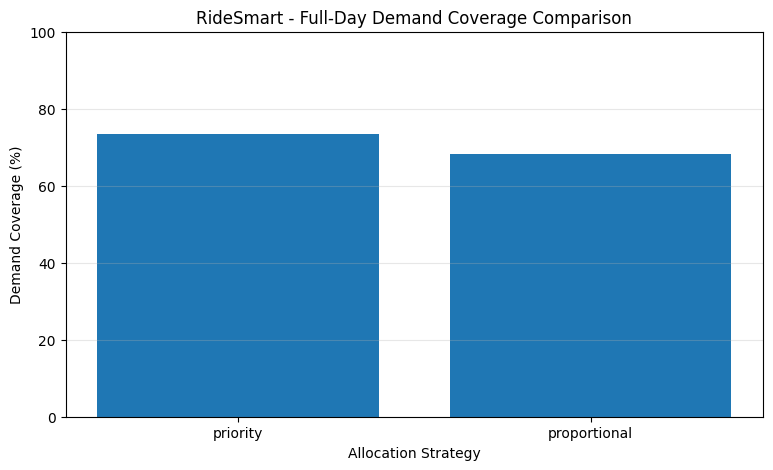

In [75]:
import matplotlib.pyplot as plt

summary = comparison_24h.groupby("strategy").agg(
    total_demand=("predicted_demand", "sum"),
    total_served=("served_demand", "sum"),
    total_unserved=("unserved_demand", "sum")
).reset_index()

summary["coverage_pct"] = (
    summary["total_served"] /
    summary["total_demand"] * 100
)

display(summary.round(2))

# Compare coverage
plt.figure(figsize=(9, 5))

plt.bar(
    summary["strategy"],
    summary["coverage_pct"]
)

plt.title("RideSmart - Full-Day Demand Coverage Comparison")
plt.ylabel("Demand Coverage (%)")
plt.xlabel("Allocation Strategy")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)

plt.show()

build vehicle movement constraints

In [76]:
print(capacity_schedule.columns.tolist())
display(capacity_schedule.head(10))

['pickup_date', 'Zone', 'pickup_hour', 'actual', 'predicted', 'average_duration', 'required_vehicles', 'allocated_vehicles', 'service_capacity', 'unserved_demand']


,pickup_date,Zone,pickup_hour,actual,predicted,average_duration,required_vehicles,allocated_vehicles,service_capacity,unserved_demand
0,2025-03-15,Midtown Center,0,88,132.282416,13.981597,36.265086,33,120.372519,11.909897
1,2025-03-15,Upper East Side South,0,78,103.358058,11.226283,22.751506,21,95.401124,7.956934
2,2025-03-15,Upper East Side North,0,40,43.076414,11.629890,9.823018,9,39.467270,3.609143
3,2025-03-15,JFK Airport,0,205,221.433290,38.515704,167.228608,151,199.944419,21.488871
4,2025-03-15,Times Sq/Theatre District,0,205,210.696384,14.958656,61.798721,56,190.926242,19.770142
5,2025-03-15,Penn Station/Madison Sq West,0,241,331.486040,14.683313,95.437518,86,298.706422,32.779618
6,2025-03-15,Midtown East,0,71,66.483494,13.422071,17.496984,16,60.795387,5.688107
7,2025-03-15,Lincoln Square East,0,120,204.703448,12.110050,48.607236,44,185.300638,19.402811
8,2025-03-15,Union Sq,0,291,252.119197,12.603363,62.304898,56,226.606180,25.513016
9,2025-03-15,Murray Hill,0,140,123.506456,13.044421,31.589611,28,109.472091,14.034366


In [77]:
def constrained_reallocation(
    capacity_data,
    fleet_size=500,
    max_moves=100
):

    data = capacity_data.copy()

    data["pickup_date"] = pd.to_datetime(data["pickup_date"])

    hours = sorted(data["pickup_hour"].unique())

    previous_allocation = None
    results = []

    for hour in hours:

        hour_data = data[
            data["pickup_hour"] == hour
        ].copy()

        # Calculate demand-priority target allocation
        target = allocate_by_strategy(
            hour_data,
            fleet_size=fleet_size,
            strategy="priority"
        )

        target_allocation = target.set_index("Zone")["allocated"]

        zones = target_allocation.index.tolist()

        if previous_allocation is None:
            current = target_allocation.copy()
        else:
            current = previous_allocation.reindex(
                zones, fill_value=0
            ).copy()

            # Move vehicles from surplus zones to deficit zones
            surplus = (current - target_allocation).clip(lower=0)
            deficit = (target_allocation - current).clip(lower=0)

            moves_left = max_moves

            for zone in deficit.sort_values(
                ascending=False
            ).index:

                amount = min(
                    int(deficit[zone]),
                    moves_left
                )

                if amount <= 0:
                    continue

                donor_zones = surplus.sort_values(
                    ascending=False
                ).index

                for donor in donor_zones:

                    transfer = min(
                        amount,
                        int(surplus[donor])
                    )

                    if transfer <= 0:
                        continue

                    current[donor] -= transfer
                    current[zone] += transfer

                    surplus[donor] -= transfer
                    amount -= transfer
                    moves_left -= transfer

                    if amount == 0 or moves_left == 0:
                        break

                if moves_left == 0:
                    break

        target = target.set_index("Zone")
        target["constrained_vehicles"] = current

        target["constrained_capacity"] = (
            target["constrained_vehicles"] *
            60 * 0.85 /
            target["average_duration"]
        )

        target["constrained_served"] = np.minimum(
            target["predicted"],
            target["constrained_capacity"]
        )

        target["constrained_unserved"] = (
            target["predicted"] -
            target["constrained_served"]
        ).clip(lower=0)

        target["hour"] = hour

        results.append(target.reset_index())

        previous_allocation = current.copy()

    return pd.concat(results, ignore_index=True)


# Run the model
movement_results = constrained_reallocation(
    capacity_data,
    fleet_size=500,
    max_moves=100
)

display(movement_results.head(10).round(2))

,Zone,pickup_date,pickup_hour,actual,predicted,average_duration,required_vehicles,allocated,service_capacity,served,unserved,constrained_vehicles,constrained_capacity,constrained_served,constrained_unserved,hour
0,Midtown Center,2025-03-15,0,88,132.28,13.98,36.27,39,142.26,132.28,0.00,39,142.26,132.28,0.00,0
1,Upper East Side South,2025-03-15,0,78,103.36,11.23,22.75,31,140.83,103.36,0.00,31,140.83,103.36,0.00,0
2,Upper East Side North,2025-03-15,0,40,43.08,11.63,9.82,13,57.01,43.08,0.00,13,57.01,43.08,0.00,0
3,JFK Airport,2025-03-15,0,205,221.43,38.52,167.23,65,86.07,86.07,135.36,65,86.07,86.07,135.36,0
4,Times Sq/Theatre District,2025-03-15,0,205,210.70,14.96,61.80,62,211.38,210.70,0.00,62,211.38,210.70,0.00,0
5,Penn Station/Madison Sq West,2025-03-15,0,241,331.49,14.68,95.44,98,340.39,331.49,0.00,98,340.39,331.49,0.00,0
6,Midtown East,2025-03-15,0,71,66.48,13.42,17.50,20,75.99,66.48,0.00,20,75.99,66.48,0.00,0
7,Lincoln Square East,2025-03-15,0,120,204.70,12.11,48.61,61,256.89,204.70,0.00,61,256.89,204.70,0.00,0
8,Union Sq,2025-03-15,0,291,252.12,12.60,62.30,75,303.49,252.12,0.00,75,303.49,252.12,0.00,0
9,Murray Hill,2025-03-15,0,140,123.51,13.04,31.59,36,140.75,123.51,0.00,36,140.75,123.51,0.00,0


In [78]:
print(
    movement_results.groupby("hour")[
        "constrained_vehicles"
    ].sum()
)

hour
0     500
1     500
2     500
3     500
4     500
5     500
6     500
7     500
8     500
9     500
10    500
11    500
12    500
13    500
14    500
15    500
16    500
17    500
18    500
19    500
20    500
21    500
22    500
23    500
Name: constrained_vehicles, dtype: int64


check vehicle movements

In [79]:
hourly_allocations = movement_results.pivot(
    index="hour",
    columns="Zone",
    values="constrained_vehicles"
).sort_index()

hourly_moves = (
    hourly_allocations.diff().abs().sum(axis=1) / 2
)

movement_check = pd.DataFrame({
    "vehicles_moved": hourly_moves,
    "maximum_allowed": 100
})

movement_check["constraint_passed"] = (
    movement_check["vehicles_moved"] <= 100
)

display(movement_check.round(0))

print("Maximum vehicles moved:",
      hourly_moves.max())

,vehicles_moved,maximum_allowed,constraint_passed
hour,,,
0,0.0,100,True
1,0.0,100,True
2,0.0,100,True
3,0.0,100,True
4,0.0,100,True
5,0.0,100,True
6,0.0,100,True
7,13.0,100,True
8,37.0,100,True


Maximum vehicles moved: 43.0


evaluate all three strategies

In [80]:
movement_summary = pd.DataFrame({
    "strategy": [
        "Proportional",
        "Demand Priority",
        "Movement Constrained"
    ],
    "served_demand": [
        comparison_24h[
            comparison_24h["strategy"] == "proportional"
        ]["served_demand"].sum(),

        comparison_24h[
            comparison_24h["strategy"] == "priority"
        ]["served_demand"].sum(),

        movement_results["constrained_served"].sum()
    ],
    "unserved_demand": [
        comparison_24h[
            comparison_24h["strategy"] == "proportional"
        ]["unserved_demand"].sum(),

        comparison_24h[
            comparison_24h["strategy"] == "priority"
        ]["unserved_demand"].sum(),

        movement_results["constrained_unserved"].sum()
    ]
})

total_demand = comparison_24h["predicted_demand"].sum()

movement_summary["coverage_pct"] = (
    movement_summary["served_demand"] /
    total_demand * 100
)

display(movement_summary.round(2))

,strategy,served_demand,unserved_demand,coverage_pct
0,Proportional,29145.77,13626.76,34.07
1,Demand Priority,31414.02,11358.51,36.72
2,Movement Constrained,31670.82,11101.71,37.02


fix the evaluation

In [81]:
# One demand value per hour, not one per strategy
hourly_demand = (
    comparison_24h
    .drop_duplicates(subset="hour")
    ["predicted_demand"]
    .sum()
)

print("Correct total daily demand:", round(hourly_demand, 2))

# Compare fleet deployment by hour
fleet_comparison = comparison_24h.pivot(
    index="hour",
    columns="strategy",
    values="vehicles_allocated"
)

fleet_comparison["movement_constrained"] = (
    movement_results.groupby("hour")[
        "constrained_vehicles"
    ].sum()
)

display(fleet_comparison)

Correct total daily demand: 42772.53


strategy,priority,proportional,movement_constrained
hour,,,
0,500,500,500
1,270,270,500
2,112,112,500
3,62,62,500
4,56,56,500
5,107,107,500
6,147,147,500
7,191,191,500
8,252,252,500


Replace the movement-constrained function

In [82]:
def constrained_reallocation_v2(
    capacity_data,
    fleet_size=500,
    max_moves=100
):
    data = capacity_data.copy()
    data["pickup_date"] = pd.to_datetime(data["pickup_date"])

    results = []
    previous = None

    for hour in sorted(data["pickup_hour"].unique()):

        hour_data = data[
            data["pickup_hour"] == hour
        ].copy().reset_index(drop=True)

        # Same deployable fleet size as the other strategies
        target_fleet = min(
            fleet_size,
            int(np.ceil(hour_data["required_vehicles"].sum()))
        )

        # Demand-priority target allocation
        weights = hour_data["predicted"].clip(lower=0)

        exact = weights / weights.sum() * target_fleet

        target = np.floor(exact).astype(int)

        remaining = target_fleet - target.sum()

        winners = (
            exact - np.floor(exact)
        ).sort_values(ascending=False).index[:remaining]

        target.loc[winners] += 1

        hour_data["target_vehicles"] = target.values

        if previous is None:
            current = hour_data["target_vehicles"].copy()
            moved = 0

        else:
            previous = previous.reindex(hour_data["Zone"]).fillna(0)

            # Reduce fleet deployment if demand falls
            if target_fleet < previous.sum():
                current = previous * (
                    target_fleet / previous.sum()
                )
                current = current.round().astype(int)

                # Correct rounding to exact fleet total
                difference = target_fleet - current.sum()

                if difference > 0:
                    current.iloc[:difference] += 1
                elif difference < 0:
                    current.iloc[:abs(difference)] -= 1

                moved = 0

            else:
                current = previous.astype(int).copy()

                # Deploy additional reserve vehicles into deficit zones
                reserve = target_fleet - current.sum()

                deficits = (hour_data["target_vehicles"].values - current.values).clip(0)

                for idx in np.argsort(-deficits):
                    addition = min(int(deficits[idx]), reserve)
                    current.iloc[idx] += addition
                    reserve -= addition

                    if reserve == 0:
                        break

                # Reposition between zones, up to the hourly limit
                surplus = (current.values - target).clip(0)
                deficit = (target.values - current.values).clip(0)

                moved = 0

                for receiver in np.argsort(-deficit):
                    for donor in np.argsort(-surplus):

                        transfer = min(
                            int(deficit[receiver]),
                            int(surplus[donor]),
                            max_moves - moved
                        )

                        if transfer <= 0:
                            continue

                        current.iloc[donor] -= transfer
                        current.iloc[receiver] += transfer

                        surplus[donor] -= transfer
                        deficit[receiver] -= transfer
                        moved += transfer

                        if moved >= max_moves:
                            break

                    if moved >= max_moves:
                        break

        hour_data["constrained_vehicles"] = current.values
        hour_data["vehicles_moved"] = moved

        hour_data["constrained_capacity"] = (
            hour_data["constrained_vehicles"] *
            60 * 0.85 /
            hour_data["average_duration"]
        )

        hour_data["constrained_served"] = np.minimum(
            hour_data["predicted"],
            hour_data["constrained_capacity"]
        )

        hour_data["constrained_unserved"] = (
            hour_data["predicted"] -
            hour_data["constrained_served"]
        ).clip(lower=0)

        results.append(hour_data)

        previous = pd.Series(
            current.values,
            index=hour_data["Zone"]
        )

    return pd.concat(results, ignore_index=True)

In [83]:
movement_results_v2 = constrained_reallocation_v2(
    capacity_data,
    fleet_size=500,
    max_moves=100
)

display(
    movement_results_v2[
        ["Zone", "pickup_hour", "target_vehicles",
         "constrained_vehicles", "vehicles_moved"]
    ].head(15)
)

,Zone,pickup_hour,target_vehicles,constrained_vehicles,vehicles_moved
0,Midtown Center,0,39,39,0
1,Upper East Side South,0,31,31,0
2,Upper East Side North,0,13,13,0
3,JFK Airport,0,65,65,0
4,Times Sq/Theatre District,0,62,62,0
5,Penn Station/Madison Sq West,0,98,98,0
6,Midtown East,0,20,20,0
7,Lincoln Square East,0,61,61,0
8,Union Sq,0,75,75,0
9,Murray Hill,0,36,36,0


In [84]:
fleet_check_v2 = movement_results_v2.groupby("pickup_hour").agg(
    allocated=("constrained_vehicles", "sum"),
    required=("required_vehicles", "sum"),
    vehicles_moved=("vehicles_moved", "first")
)

display(fleet_check_v2.round(2))

,allocated,required,vehicles_moved
pickup_hour,,,
0,500,553.30,0
1,270,269.25,0
2,112,111.58,0
3,62,61.83,0
4,56,55.73,0
5,107,106.18,6
6,147,146.45,0
7,191,190.62,1
8,252,251.07,22


In [85]:
# Calculate revised movement-constrained performance

total_demand = (
    movement_results_v2["predicted"].sum()
)

total_served = (
    movement_results_v2["constrained_served"].sum()
)

total_unserved = (
    movement_results_v2["constrained_unserved"].sum()
)

coverage = total_served / total_demand * 100

print("Total predicted demand:", round(total_demand, 2))
print("Total served demand:", round(total_served, 2))
print("Total unserved demand:", round(total_unserved, 2))
print("Demand coverage:", round(coverage, 2), "%")

Total predicted demand: 42772.53
Total served demand: 31348.71
Total unserved demand: 11423.82
Demand coverage: 73.29 %


In [86]:
print("Total fleet by hour:")

display(
    movement_results_v2.groupby("pickup_hour")[
        "constrained_vehicles"
    ].sum()
)

print("Maximum vehicles moved in one hour:",
      movement_results_v2.groupby("pickup_hour")[
          "vehicles_moved"
      ].first().max())

Total fleet by hour:


,constrained_vehicles
pickup_hour,
0,500
1,270
2,112
3,62
4,56
5,107
6,147
7,191
8,252


Maximum vehicles moved in one hour: 43


Revised model results
Metric	Result
Total predicted demand	42,772.53
Total served demand	31,348.71
Total unserved demand	11,423.82
Demand coverage	73.29%
Fleet limit	500 vehicles
Maximum vehicles moved/hour	43
Movement limit	100 vehicles/hour

The model serves approximately 73.29% of predicted demand while respecting the fleet limit and our simulated movement constraint.
2. Final comparison of the three strategies
Strategy	Served pickups	Coverage
Proportional	29,145.77	68.14%
Demand Priority	31,414.02	73.44%
Movement Constrained	31,348.71	73.29%

RideSmart allocation strategy comparison
Estimated demand coverage across 24 hours on March 15, 2025.

Demand Priority

Demand coverage73.4%

Our finding: The movement-constrained strategy serves 65.31 fewer pickups than unrestricted demand-priority allocation, a difference of just 0.15 percentage points in coverage.

That is a useful trade-off: we retain almost all the estimated service performance while limiting inter-zone allocation changes.

In [87]:
import os

# Create a folder for RideSmart dashboard data
os.makedirs("ridesmart_data", exist_ok=True)

# Save the main datasets
capacity_data.to_csv(
    "ridesmart_data/capacity_data.csv",
    index=False
)

movement_results_v2.to_csv(
    "ridesmart_data/movement_results.csv",
    index=False
)

comparison_24h.to_csv(
    "ridesmart_data/strategy_comparison.csv",
    index=False
)

movement_summary.to_csv(
    "ridesmart_data/previous_strategy_summary.csv",
    index=False
)

print("RideSmart datasets saved successfully!")

RideSmart datasets saved successfully!


In [88]:
import shutil
from google.colab import files

shutil.make_archive(
    "ridesmart_data",
    "zip",
    "ridesmart_data"
)

files.download("ridesmart_data.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [90]:
import pandas as pd

zones = pd.read_csv(
    "https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv"
)

print(zones.shape)
display(zones.head())

(265, 4)


,LocationID,Borough,Zone,service_zone
0,1,EWR,Newark Airport,EWR
1,2,Queens,Jamaica Bay,Boro Zone
2,3,Bronx,Allerton/Pelham Gardens,Boro Zone
3,4,Manhattan,Alphabet City,Yellow Zone
4,5,Staten Island,Arden Heights,Boro Zone
